# Comparative Intelligence and Ethics in Machine Learning Systems
## Paediatric pneumonia detection from chest X-rays: classical ML vs deep learning

**Track A: Computer Vision.** Binary classification: `NORMAL` vs `PNEUMONIA`.

| Section | Contents |
|---|---|
| 1 | Setup and reproducibility |
| 2 | Dataset: provenance, loading, exploratory analysis |
| 3 | Preprocessing |
| 4 | Validation strategy: patient-grouped stratified 5-fold CV + held-out test |
| 5 | Classical model: HOG features + SVM |
| 6 | Deep model: fine-tuned ResNet-18 CNN |
| 7 | Held-out test evaluation and comparison |
| 8 | Explainability: Grad-CAM (CNN) and LIME (both models) |
| 9 | Bias and diagnostic analysis: subgroups and robustness |
| 10 | Mitigation experiment: border crop + CLAHE |
| 11 | Demo: single-image inference |
| 12 | Ethics, recommendation, deployment, limitations and references |
| 13 | Save results |

Figures are saved to `figures/` for use in the presentation.

## 1. Setup and reproducibility

**Tool choices**
- **scikit-learn** for the classical pipeline. It is the standard library for classical ML and offers
  `Pipeline`, `GridSearchCV` and `StratifiedGroupKFold`, so feature scaling and PCA are fitted inside each fold with no leakage.
- **scikit-image** for HOG feature extraction.
- **PyTorch + torchvision** for the CNN. It gives ImageNet-pretrained ResNet weights, runs natively on CUDA,
  and has simple hooks for Grad-CAM.
- **pytorch-grad-cam** and **LIME** for explainability. Grad-CAM is specific to CNNs. LIME is model-agnostic,
  so it can explain *both* models in the same way, which makes the comparison fair.

In [1]:
import time, json, zipfile, re, random, copy, pickle, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.base import clone
from scipy.stats import binomtest
import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             ConfusionMatrixDisplay)
from skimage.feature import hog
from skimage.transform import resize
from skimage.segmentation import mark_boundaries
from lime import lime_image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Silence known-noisy library warnings only (torchvision/sklearn deprecation notices), keep everything else visible
warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")
# With mixed precision, GradScaler skips the optimiser step on the first batches if gradients overflow; PyTorch then
# warns that the LR scheduler stepped first. This is expected and harmless.
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step()` before `optimizer.step()`")

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
# Deterministic cuDNN kernels reduce run-to-run variation (a few CUDA backward ops remain non-deterministic,
# so CNN results can still differ in the last decimal place between machines)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
RAW_ZIP = ROOT / "data" / "raw" / "ChestXRay2017.zip"
RAW_DIR = ROOT / "data" / "raw" / "ChestXRay2017"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
MODEL_DIR = ROOT / "models"
for d in (PROC_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

IMG_SIZE = 224        # CNN input resolution (ResNet's native ImageNet size)
CLASSICAL_SIZE = 128  # downsampled resolution for HOG features
N_FOLDS = 5
CLASSES = ["NORMAL", "PNEUMONIA"]

sns.set_theme(style="whitegrid", context="talk")
PALETTE = {"SVM (HOG)": "#4C72B0", "ResNet-18": "#DD8452"}

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

print(f"PyTorch {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

PyTorch 2.11.0+cu128 | device: cuda (NVIDIA GeForce RTX 5070 Ti Laptop GPU)


## 2. Dataset

**Source:** Kermany, D. et al. (2018) *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning*,
Cell 172(5). Data: Mendeley Data, doi:10.17632/rscbjbr9sj.2 (licence CC BY 4.0). The widely used Kaggle
"Chest X-Ray Images (Pneumonia)" dataset is a re-upload of this release. We use the original source because it
documents provenance more clearly.

**Provenance:** anterior-posterior chest X-rays of paediatric patients aged 1–5 at Guangzhou Women and Children's
Medical Center, collected as part of routine clinical care. Experts graded the labels, and a third expert checked the test set.

**Why this dataset?**
- It is a real clinical task where errors have asymmetric consequences, which grounds the ethics discussion.
- Filenames encode **patient IDs**, so we can build a leakage-free, patient-grouped validation. Person numbers restart for
  each pneumonia subtype (`person12_bacteria` and `person12_virus` are different children), so the ID combines subtype and number.
  With that ID, the official train and test splits share no patients (checked below).
- Filenames also encode **bacterial vs viral** pneumonia, which gives a clinically meaningful subgroup.
- Its size (~5.9k images) is small enough for a classical model to be competitive. That makes the classical-vs-DL comparison a real one.

In [2]:
if not RAW_DIR.exists():
    with zipfile.ZipFile(RAW_ZIP) as zf:
        members = [m for m in zf.namelist() if not m.startswith("__MACOSX") and not Path(m).name.startswith(".")]
        zf.extractall(RAW_DIR, members=members)

# Locate the train/test folders wherever they sit inside the archive
base = next(p.parent for p in RAW_DIR.rglob("train") if (p / "NORMAL").is_dir())
print("Data root:", base.relative_to(ROOT))

def parse_meta(path: Path, split: str) -> dict:
    """Extract label, pneumonia subtype and patient ID from the filename convention."""
    label = path.parent.name
    name = path.stem
    if label == "PNEUMONIA":
        # e.g. person1000_bacteria_2931 / person1000_virus_1681
        # person numbers restart for each subtype: person12_bacteria and person12_virus are different children
        m = re.match(r"(person\d+)_(bacteria|virus)", name)
        subtype = m.group(2)
        patient = f"{subtype}:{m.group(1)}"
    else:
        # e.g. IM-0115-0001 / NORMAL2-IM-0427-0001
        m = re.match(r"((?:NORMAL2-)?IM-\d+)", name)
        patient, subtype = m.group(1), "normal"
    # normal images come in two filename families (IM-xxxx and NORMAL2-IM-xxxx), which look like separate collection batches
    batch = ("NORMAL2" if name.startswith("NORMAL2") else "IM") if label == "NORMAL" else "pneumonia"
    return {"path": str(path), "split": split, "label": label, "y": int(label == "PNEUMONIA"),
            "subtype": subtype, "patient": f"{label}:{patient}", "batch": batch}

records = [parse_meta(p, split)
           for split in ("train", "test")
           for p in sorted((base / split).glob("*/*.jpeg"))]
meta = pd.DataFrame(records)
print(meta.groupby(["split", "label"]).size().unstack())
print("\nUnique patients per split:", meta.groupby("split").patient.nunique().to_dict())
overlap = set(meta.query("split=='train'").patient) & set(meta.query("split=='test'").patient)
print("Patients appearing in both train and test:", len(overlap))

# Evidence that person numbers restart per subtype: if 'personN' alone were the patient ID, the official split would
# share patients between train and test; keyed by subtype, it shares none.
naive_id = meta.patient.str.replace(r"(bacteria|virus):", "", regex=True)
print("Train/test overlap if person numbers were shared across subtypes:",
      len(set(naive_id[meta.split == "train"]) & set(naive_id[meta.split == "test"])))

Data root: data\raw\ChestXRay2017\chest_xray
label  NORMAL  PNEUMONIA
split                   
test      234        390
train    1349       3883

Unique patients per split: {'test': 428, 'train': 3669}
Patients appearing in both train and test: 0
Train/test overlap if person numbers were shared across subtypes: 170


### 2.1 Exploratory analysis

reading headers:   0%|          | 0/5856 [00:00<?, ?it/s]

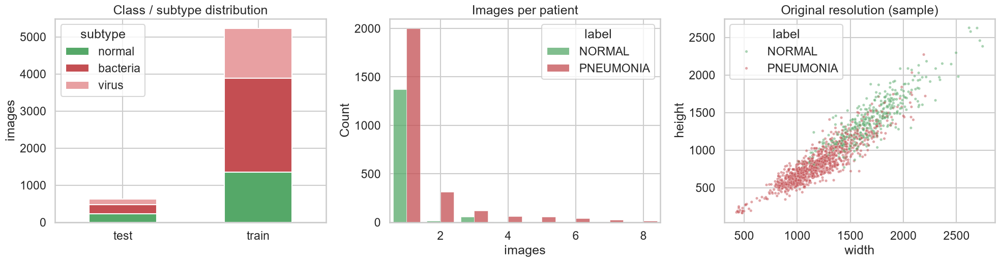

Image modes: {'L': 5573, 'RGB': 283}
Train class ratio PNEUMONIA:NORMAL = 2.88 : 1


In [3]:
# Image dimensions (read headers only, which is fast)
sizes = [Image.open(p).size for p in tqdm(meta.path, desc="reading headers")]
meta["width"], meta["height"] = zip(*sizes)
meta["mode"] = [Image.open(p).mode for p in meta.path]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
counts = meta.groupby(["split", "subtype"]).size().unstack()[["normal", "bacteria", "virus"]]
counts.plot.bar(stacked=True, ax=axes[0], color=["#55A868", "#C44E52", "#E8A0A2"], rot=0)
axes[0].set_title("Class / subtype distribution"); axes[0].set_ylabel("images"); axes[0].set_xlabel("")
img_per_patient = meta.groupby(["label", "patient"]).size().rename("n").reset_index()
CLASS_PALETTE = {"NORMAL": "#55A868", "PNEUMONIA": "#C44E52"}
sns.histplot(data=img_per_patient, x="n", hue="label", hue_order=CLASSES, palette=CLASS_PALETTE, discrete=True, multiple="dodge", ax=axes[1], shrink=.8)
axes[1].set_xlim(0.5, 8.5); axes[1].set_title("Images per patient"); axes[1].set_xlabel("images")
sns.scatterplot(data=meta.sample(1500, random_state=SEED), x="width", y="height", hue="label", hue_order=CLASSES, palette=CLASS_PALETTE, alpha=.5, s=15, ax=axes[2])
axes[2].set_title("Original resolution (sample)")
plt.tight_layout(); savefig("eda_distribution"); plt.show()

print("Image modes:", meta["mode"].value_counts().to_dict())
print("Train class ratio PNEUMONIA:NORMAL = %.2f : 1" %
      (meta.query("split=='train'").y.mean() / (1 - meta.query("split=='train'").y.mean())))

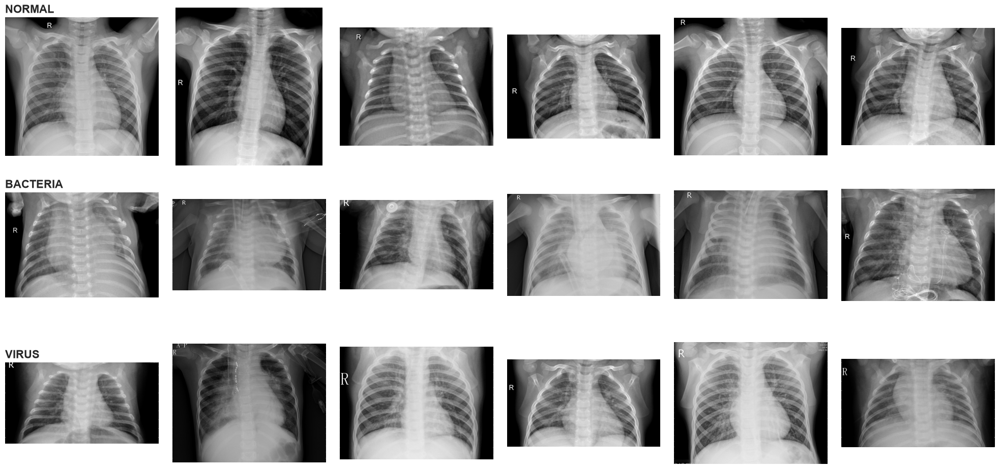

In [4]:
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
for row, sub in zip(axes, ["normal", "bacteria", "virus"]):
    for ax, p in zip(row, meta.query("split=='train' and subtype==@sub").sample(6, random_state=SEED).path):
        ax.imshow(Image.open(p).convert("L"), cmap="gray"); ax.axis("off")
    row[0].set_title(sub.upper(), loc="left", fontsize=16, fontweight="bold")
plt.tight_layout(); savefig("eda_samples"); plt.show()

**Observations that shape the design**
1. **Class imbalance** (~2.9 : 1 pneumonia : normal in training). We use class weighting and report precision, recall and F1, not just accuracy.
2. **Several images per patient.** Splitting at random by image would let the same patient appear in both training and validation folds,
   which inflates the scores (leakage). We therefore **group folds by patient**.
3. **Resolutions and aspect ratios vary**, and some files are RGB rather than greyscale. Everything is converted to a single greyscale channel and resized to a fixed size.
4. **Acquisition confound:** NORMAL images are systematically *higher resolution* than PNEUMONIA images (right-hand plot).
   Resizing removes the raw resolution, but framing and anatomical scale may still differ by class. A model could learn
   *how the image was acquired* rather than *what is in the lungs*. We keep this in mind for the XAI and bias analysis.
5. **Burnt-in text markers** (e.g. "R" side markers) and borders appear in many images. A model could learn these as shortcuts, which we check with XAI in Section 8.

## 3. Preprocessing

- Convert to **8-bit greyscale**. X-rays are single-channel; the few RGB files carry no extra information.
- **Resize to 224×224** with antialiasing. Squashing the aspect ratio keeps the full lung fields; centre-cropping could cut off the lung bases or apices.
- Cache everything as a `uint8` array (about 290 MB), so both models read exactly the same pixels and repeated decoding of JPEGs is avoided.
- We record each image's **mean brightness** and **contrast** (pixel std) for the subgroup analysis in Section 9.

Intensity normalisation is model-specific and is done later: standardisation inside the SVM pipeline, ImageNet statistics for the CNN.

In [5]:
# Only the pixel array is cached; metadata is always rebuilt from the filenames above, so it cannot go stale.
cache_X = PROC_DIR / f"images_{IMG_SIZE}.npy"
cache_paths = PROC_DIR / f"images_{IMG_SIZE}_paths.txt"
if cache_X.exists() and cache_paths.exists() and cache_paths.read_text().splitlines() == list(meta.path):
    X_all = np.load(cache_X)
else:
    X_all = np.stack([np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS))
                      for p in tqdm(meta.path, desc="preprocessing")])
    np.save(cache_X, X_all); cache_paths.write_text("\n".join(meta.path))
meta["brightness"] = X_all.reshape(len(X_all), -1).mean(1)
meta["contrast"] = X_all.reshape(len(X_all), -1).std(1)
meta.to_csv(PROC_DIR / "meta.csv", index=False)   # for reference only; not read back

train_idx = np.where(meta.split == "train")[0]
test_idx = np.where(meta.split == "test")[0]
y_all = meta.y.values
print("Cached array:", X_all.shape, X_all.dtype, f"{X_all.nbytes/1e6:.0f} MB")

Cached array: (5856, 224, 224) uint8 294 MB


## 4. Validation strategy

**Why validation matters.** A model's score on the data it was trained on says little about how it will perform on new patients.
A flexible model such as a CNN with 11M parameters can memorise the training set. Validation estimates *generalisation*
and lets us tune hyperparameters and detect overfitting without touching the test set.

**Our design: two levels**
1. **Patient-grouped, stratified 5-fold cross-validation** on the training set (`StratifiedGroupKFold`).
   - *Grouped*: every image of a patient falls in the same fold, which prevents patient-level leakage.
   - *Stratified*: each fold keeps the ~74 % pneumonia rate, so fold scores are comparable.
   - Five folds give a **mean ± std** for each metric. We get a measure of uncertainty as well as a single number.
   - Both models use **identical folds**, so the comparison is paired.
2. **Official held-out test set** (624 images from patients who do not appear in training, labels checked by a third expert).
   It is **never** used for training, hyperparameter tuning or early stopping. It is used for the final comparison and the
   diagnostic analyses that follow (subgroups, stress test, mitigation). Because the final model choice in Section 12 also
   looks at these results, the reported test numbers are slightly optimistic for the *chosen* model. A truly external test set would remove this.

We discard the official 16-image validation split from the Kaggle version. It is far too small to estimate generalisation, and the k-fold scheme replaces it.

In [6]:
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(sgkf.split(train_idx, y_all[train_idx], groups=meta.patient.values[train_idx]))  # positions within train_idx

fold_summary = []
for k, (tr, va) in enumerate(folds):
    leak = set(meta.patient.values[train_idx][tr]) & set(meta.patient.values[train_idx][va])
    fold_summary.append({"fold": k, "train": len(tr), "val": len(va),
                         "val % pneumonia": round(100 * y_all[train_idx][va].mean(), 1), "shared patients": len(leak)})
pd.DataFrame(fold_summary)

,fold,train,val,val % pneumonia,shared patients
0,0,4185,1047,74.2,0
1,1,4185,1047,74.2,0
2,2,4186,1046,74.3,0
3,3,4186,1046,74.2,0
4,4,4186,1046,74.2,0


### 4.1 Shared evaluation helpers
The positive class is **PNEUMONIA**. *Recall* (sensitivity) is the proportion of sick children the model detects;
*precision* is the proportion of flagged children who really have pneumonia. We also report *specificity*
(recall on normal cases) and ROC-AUC, which does not depend on the decision threshold.

In [7]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "roc_auc": roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else np.nan,
            "FN": int(fn), "FP": int(fp)}

METRICS = ["accuracy", "precision", "recall", "f1", "specificity", "roc_auc"]

## 5. Classical model: HOG features + RBF-kernel SVM

**Design rationale**
- Classical models cannot use raw pixels well (50k correlated features, no translation invariance), so we **hand-engineer features**:
  - **Histogram of Oriented Gradients (HOG)** at 128×128 (16 px cells, 2×2 blocks, 9 orientations → 1,764 features).
    HOG captures local edge structure: rib outlines, clear lung borders, and the blurred, patchy texture of consolidation.
  - A **32-bin intensity histogram**, since pneumonia appears as increased opacity (whiter lung fields).
- **StandardScaler → PCA (95 % variance) → SVM with RBF kernel.** PCA removes redundancy between neighbouring HOG cells and
  speeds up the SVM. The RBF kernel models non-linear boundaries. SVMs work well in this regime of medium-sized, high-dimensional data.
- `class_weight="balanced"` offsets the 2.9:1 imbalance.
- **Hyperparameters** (`C`, `gamma`) are tuned with grid search on the *same patient-grouped folds*, selecting on F1.
  Scaling and PCA sit inside the pipeline, so they are re-fitted on each training fold, which avoids leakage.

In [8]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")

def classical_features(imgs_u8: np.ndarray) -> np.ndarray:
    """imgs_u8: (N, H, W) uint8 greyscale → (N, 1796) HOG + intensity histogram."""
    feats = []
    for img in imgs_u8:
        small = resize(img, (CLASSICAL_SIZE, CLASSICAL_SIZE), anti_aliasing=True)  # float in [0, 1]
        h = hog(small, **HOG_PARAMS)
        hist = np.histogram(small, bins=32, range=(0, 1), density=True)[0]
        feats.append(np.concatenate([h, hist]))
    return np.asarray(feats, dtype=np.float32)

t0 = time.time()
F_all = classical_features(X_all)
feat_time = time.time() - t0
print(f"Feature matrix {F_all.shape} in {feat_time:.0f}s")

Feature matrix (5856, 1796) in 11s


In [9]:
svm_pipe = Pipeline([("scale", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=SEED)),
                     ("svm", SVC(kernel="rbf", class_weight="balanced", random_state=SEED))])
# Probability calibration (Platt scaling) is only switched on for the per-fold and final fits; the grid search
# scores with decision_function, which skips 5× the work. Note: Platt scaling fits on an internal 5-fold split that is
# not patient-grouped; this only affects how decision values map to probabilities, not which images are used for training.
param_grid = {"svm__C": [0.3, 1, 3, 10, 30, 100], "svm__gamma": ["scale", 3e-4, 1e-3, 3e-3]}
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

t0 = time.time()
grid = GridSearchCV(svm_pipe, param_grid, cv=folds, scoring=scoring, refit=False, n_jobs=-1, verbose=0)
grid.fit(F_all[train_idx], y_all[train_idx])
svm_cv_time = time.time() - t0

res = pd.DataFrame(grid.cv_results_)
best = res.loc[res.rank_test_f1.idxmin()]
best_params = best.params
print(f"Grid search: {svm_cv_time:.0f}s | best params: {best_params}")
res[["param_svm__C", "param_svm__gamma", "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_roc_auc"]] \
    .sort_values("mean_test_f1", ascending=False).head(6).round(3)

Grid search: 84s | best params: {'svm__C': 10, 'svm__gamma': 'scale'}


,param_svm__C,param_svm__gamma,mean_test_f1,std_test_f1,mean_test_recall,mean_test_roc_auc
16,30.0,scale,0.984,0.003,0.985,0.997
20,100.0,scale,0.984,0.003,0.985,0.997
12,10.0,scale,0.984,0.003,0.985,0.997
8,3.0,scale,0.984,0.002,0.983,0.997
21,100.0,0.0003,0.984,0.001,0.983,0.997
17,30.0,0.0003,0.984,0.001,0.983,0.997


For each fold we refit the best configuration and collect out-of-fold probabilities. This gives per-fold metrics
(including specificity) that are directly comparable with the CNN's.

*Caveat:* we choose the hyperparameters and report CV performance on the same folds, so the CV score is slightly optimistic.
The same applies to the CNN, whose best epoch is chosen on the validation fold it is then scored on. Nested CV would remove
this bias at about 5× the cost. The held-out test set in Section 7 is the independent check.

In [10]:
svm_fold_metrics, svm_oof = [], np.zeros(len(train_idx))
for k, (tr, va) in enumerate(folds):
    fold_model = clone(svm_pipe).set_params(**best_params, svm__probability=True).fit(F_all[train_idx][tr], y_all[train_idx][tr])
    svm_oof[va] = fold_model.predict_proba(F_all[train_idx][va])[:, 1]
    svm_fold_metrics.append({"fold": k, **compute_metrics(y_all[train_idx][va], svm_oof[va])})
svm_cv = pd.DataFrame(svm_fold_metrics)
svm_cv[METRICS].agg(["mean", "std"]).round(3)

,accuracy,precision,recall,f1,specificity,roc_auc
mean,0.976,0.983,0.984,0.984,0.952,0.997
std,0.005,0.008,0.004,0.003,0.023,0.000


In [11]:
# Final classical model: refit on the full training set
t0 = time.time()
svm_final = clone(svm_pipe).set_params(**best_params, svm__probability=True).fit(F_all[train_idx], y_all[train_idx])
svm_train_time = time.time() - t0
joblib.dump(svm_final, MODEL_DIR / "svm_hog.joblib")
print(f"Final SVM fit: {svm_train_time:.1f}s | PCA components kept: {svm_final.named_steps['pca'].n_components_}"
      f" | support vectors: {svm_final.named_steps['svm'].n_support_.sum()}")

Final SVM fit: 4.2s | PCA components kept: 455 | support vectors: 1116


## 6. Deep learning model: fine-tuned ResNet-18

**Design rationale**
- **Architecture: ResNet-18** pre-trained on ImageNet (11.2M parameters). Residual connections make it stable to fine-tune.
  It is small enough to avoid severe overfitting on ~4k training images, and its last convolutional block (`layer4`) suits Grad-CAM.
  Larger networks (ResNet-50, ViT) would add capacity that this small dataset cannot use.
- **Transfer learning** rather than training from scratch: low-level ImageNet filters (edges, textures) transfer to radiographs,
  which cuts the data and compute needed. We fine-tune **all layers** with a small learning rate.
- **Input:** the greyscale image is repeated to 3 channels and normalised with ImageNet statistics, to match the pre-training.
- **Augmentation** (training only): small random rotations (±10°), shifts (±5 %), zoom (0.9–1.1), and brightness/contrast jitter (±15 %).
  These mimic differences in patient positioning and exposure. **No horizontal flip**: the heart sits on the left, so flipping produces anatomically implausible images.
- **Imbalance:** class-weighted cross-entropy (weights inversely proportional to class frequency).
- **Optimiser:** AdamW (lr 1e-4, weight decay 1e-4) with cosine learning-rate decay. Batch size 64, 12 epochs, mixed precision (AMP) for speed.
- **Early stopping:** in each fold we keep the epoch with the lowest validation loss. The final model trains on all training data for the
  *median best epoch* across folds, so the test set is never used for model selection.

**Engineering note.** The whole dataset (290 MB) is kept on the GPU and augmented there in batches. This avoids
Windows DataLoader multiprocessing problems inside notebooks and makes an epoch take a few seconds.

In [12]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)
CNN_CFG = dict(epochs=12, batch_size=64, lr=1e-4, weight_decay=1e-4)

X_gpu = torch.tensor(X_all, device=DEVICE)           # (N, 224, 224) uint8 on GPU (a copy, so the cached array stays read-only-safe)
y_gpu = torch.from_numpy(y_all).long().to(DEVICE)

def to_input(x_u8: torch.Tensor) -> torch.Tensor:
    """uint8 (B, H, W) → normalised float (B, 3, H, W)."""
    x = x_u8.float().div(255).unsqueeze(1).expand(-1, 3, -1, -1)
    return (x - IMAGENET_MEAN) / IMAGENET_STD

def augment(x_u8: torch.Tensor) -> torch.Tensor:
    """Per-sample random affine + brightness/contrast jitter, done on the GPU. Returns float in [0, 1], (B, 1, H, W)."""
    B = x_u8.shape[0]
    x = x_u8.float().div(255).unsqueeze(1)
    ang = torch.empty(B, device=DEVICE).uniform_(-10, 10) * np.pi / 180
    scale = torch.empty(B, device=DEVICE).uniform_(0.9, 1.1)
    tx, ty = (torch.empty(B, device=DEVICE).uniform_(-0.1, 0.1) for _ in range(2))  # ±5 % of width (grid spans [-1, 1])
    cos, sin = torch.cos(ang) / scale, torch.sin(ang) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="border", align_corners=False)
    b = torch.empty(B, 1, 1, 1, device=DEVICE).uniform_(-0.15, 0.15)
    c = torch.empty(B, 1, 1, 1, device=DEVICE).uniform_(0.85, 1.15)
    mean = x.mean((2, 3), keepdim=True)
    return ((x - mean) * c + mean + b).clamp(0, 1)

def normalise(x01: torch.Tensor) -> torch.Tensor:
    return (x01.expand(-1, 3, -1, -1) - IMAGENET_MEAN) / IMAGENET_STD

def build_resnet18() -> nn.Module:
    net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    net.fc = nn.Linear(net.fc.in_features, 2)   # new 2-class head (NORMAL, PNEUMONIA)
    return net.to(DEVICE)

@torch.no_grad()
def predict_proba_cnn(model, idx, batch_size=256, X=None):
    X = X_gpu if X is None else X
    model.eval()
    out = []
    for i in range(0, len(idx), batch_size):
        xb = to_input(X[idx[i:i + batch_size]])
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            out.append(torch.softmax(model(xb).float(), 1)[:, 1])
    return torch.cat(out).cpu().numpy()

def train_cnn(tr_idx, va_idx=None, epochs=CNN_CFG["epochs"], seed=SEED, verbose=True, X=None):
    """Train ResNet-18 on global indices tr_idx (images from X, default: the cached array on the GPU).
    If va_idx is given, track validation loss each epoch and restore the best epoch's weights."""
    X = X_gpu if X is None else X
    seed_everything(seed)
    model = build_resnet18()
    pos_frac = y_all[tr_idx].mean()
    class_w = torch.tensor([0.5 / (1 - pos_frac), 0.5 / pos_frac], device=DEVICE, dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=class_w)
    opt = torch.optim.AdamW(model.parameters(), lr=CNN_CFG["lr"], weight_decay=CNN_CFG["weight_decay"])
    steps_per_epoch = int(np.ceil(len(tr_idx) / CNN_CFG["batch_size"]))
    # Schedule length is fixed to the full CV budget, so the final model (trained for fewer epochs) follows exactly
    # the same learning-rate path as the fold models up to its stopping epoch.
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CNN_CFG["epochs"] * steps_per_epoch)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    tr_t = torch.from_numpy(tr_idx).to(DEVICE)
    history, best_state, best_loss = [], None, np.inf

    for ep in range(1, epochs + 1):
        model.train(); run_loss = 0.0
        perm = tr_t[torch.randperm(len(tr_t), device=DEVICE)]
        for i in range(0, len(perm), CNN_CFG["batch_size"]):
            bi = perm[i:i + CNN_CFG["batch_size"]]
            xb, yb = normalise(augment(X[bi])), y_gpu[bi]
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                loss = crit(model(xb), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(bi)
        rec = {"epoch": ep, "train_loss": run_loss / len(tr_idx)}
        if va_idx is not None:
            p = predict_proba_cnn(model, va_idx, X=X)
            p_t = torch.from_numpy(np.clip(p, 1e-7, 1 - 1e-7))
            yv = torch.from_numpy(y_all[va_idx])
            # class-weighted validation log-loss (same weighting as training, so the curves are comparable)
            w = class_w.cpu()[yv]
            nll = -(yv * torch.log(p_t) + (1 - yv) * torch.log(1 - p_t))
            rec["val_loss"] = float((w * nll).sum() / w.sum())
            rec.update({f"val_{k}": v for k, v in compute_metrics(y_all[va_idx], p).items() if k in ("f1", "recall", "roc_auc")})
            if rec["val_loss"] < best_loss:
                best_loss, best_state = rec["val_loss"], {k: v.detach().clone() for k, v in model.state_dict().items()}
                rec["best"] = True
        history.append(rec)
        if verbose:
            print("  " + " | ".join(f"{k}={v:.4f}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()))
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

C:\Users\ali4l\AppData\Local\Temp\ipykernel_11624\1571701017.py:6: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y_gpu = torch.from_numpy(y_all).long().to(DEVICE)


In [13]:
cnn_fold_metrics, cnn_oof, cnn_histories = [], np.zeros(len(train_idx)), []
t0 = time.time()
for k, (tr, va) in enumerate(folds):
    print(f"Fold {k}")
    model, hist = train_cnn(train_idx[tr], train_idx[va])
    cnn_oof[va] = predict_proba_cnn(model, train_idx[va])
    best_ep = int(hist.loc[hist.val_loss.idxmin(), "epoch"])
    cnn_fold_metrics.append({"fold": k, "best_epoch": best_ep, **compute_metrics(y_all[train_idx][va], cnn_oof[va])})
    cnn_histories.append(hist.assign(fold=k))
    del model; torch.cuda.empty_cache()
cnn_cv_time = time.time() - t0
cnn_cv = pd.DataFrame(cnn_fold_metrics)
print(f"\nCNN 5-fold CV: {cnn_cv_time/60:.1f} min")
cnn_cv[METRICS].agg(["mean", "std"]).round(3)

Fold 0


C:\Users\ali4l\AppData\Local\Temp\ipykernel_11624\1571701017.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  epoch=1 | train_loss=0.1331 | val_loss=0.0555 | val_recall=0.9833 | val_f1=0.9884 | val_roc_auc=0.9980 | best=True


  epoch=2 | train_loss=0.0610 | val_loss=0.0838 | val_recall=0.9511 | val_f1=0.9743 | val_roc_auc=0.9984


  epoch=3 | train_loss=0.0403 | val_loss=0.0363 | val_recall=0.9794 | val_f1=0.9883 | val_roc_auc=0.9994 | best=True


...

  epoch=10 | train_loss=0.0056 | val_loss=0.0412 | val_recall=0.9936 | val_f1=0.9942 | val_roc_auc=0.9992


  epoch=11 | train_loss=0.0042 | val_loss=0.0400 | val_recall=0.9923 | val_f1=0.9942 | val_roc_auc=0.9992


  epoch=12 | train_loss=0.0083 | val_loss=0.0396 | val_recall=0.9923 | val_f1=0.9942 | val_roc_auc=0.9992 | best=True



CNN 5-fold CV: 3.0 min


,accuracy,precision,recall,f1,specificity,roc_auc
mean,0.990,0.997,0.990,0.993,0.990,0.999
std,0.003,0.003,0.003,0.002,0.008,0.000


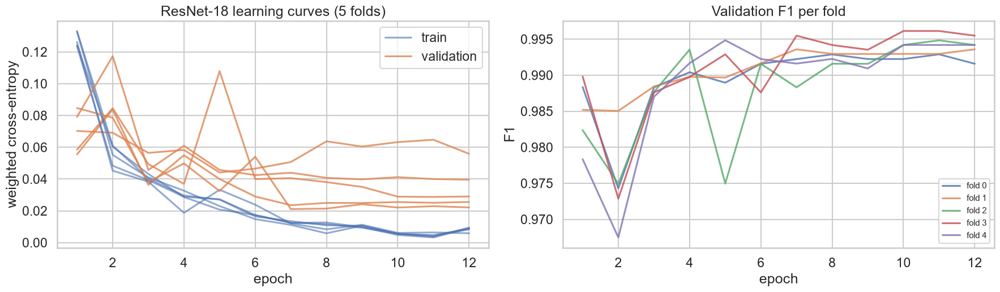

In [14]:
hists = pd.concat(cnn_histories)
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for k, h in hists.groupby("fold"):
    axes[0].plot(h.epoch, h.train_loss, color="#4C72B0", alpha=.6, label="train" if k == 0 else None)
    axes[0].plot(h.epoch, h.val_loss, color="#DD8452", alpha=.8, label="validation" if k == 0 else None)
    axes[1].plot(h.epoch, h.val_f1, alpha=.8, label=f"fold {k}")
axes[0].set(title="ResNet-18 learning curves (5 folds)", xlabel="epoch", ylabel="weighted cross-entropy"); axes[0].legend()
axes[1].set(title="Validation F1 per fold", xlabel="epoch", ylabel="F1"); axes[1].legend(fontsize=11)
plt.tight_layout(); savefig("cnn_learning_curves"); plt.show()

Training loss keeps falling towards zero in every fold, while validation loss is noisier and flattens out in the later epochs.
The gap between the two curves is the signature of overfitting (the network fitting the training images better than new
patients), which is exactly what validation exists to detect. Early stopping keeps the best epoch per fold (printed below),
and the final model trains for the median best epoch. Where the best epoch is the last one, slightly longer training might
still help; we kept 12 epochs to bound compute.

In [15]:
final_epochs = int(np.median(cnn_cv.best_epoch))
print("Best epoch per fold:", cnn_cv.best_epoch.tolist())
print(f"Training final CNN on all {len(train_idx)} training images for {final_epochs} epochs")
t0 = time.time()
cnn_final, _ = train_cnn(train_idx, None, epochs=final_epochs)
cnn_train_time = time.time() - t0
torch.save(cnn_final.state_dict(), MODEL_DIR / "resnet18_pneumonia.pt")
print(f"Final CNN fit: {cnn_train_time:.0f}s")

Best epoch per fold: [7, 5, 11, 7, 12]
Training final CNN on all 5232 training images for 7 epochs


C:\Users\ali4l\AppData\Local\Temp\ipykernel_11624\1571701017.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


  epoch=1 | train_loss=0.1279


  epoch=2 | train_loss=0.0493


  epoch=3 | train_loss=0.0358


  epoch=4 | train_loss=0.0293


  epoch=5 | train_loss=0.0248


  epoch=6 | train_loss=0.0163


  epoch=7 | train_loss=0.0130
Final CNN fit: 26s


## 7. Held-out test evaluation and comparison

In [16]:
p_test = {"SVM (HOG)": svm_final.predict_proba(F_all[test_idx])[:, 1],
          "ResNet-18": predict_proba_cnn(cnn_final, test_idx)}
y_test = y_all[test_idx]

cv_table = pd.concat({"SVM (HOG)": svm_cv[METRICS].agg(["mean", "std"]),
                      "ResNet-18": cnn_cv[METRICS].agg(["mean", "std"])})
test_table = pd.DataFrame({name: compute_metrics(y_test, p) for name, p in p_test.items()}).T
print("5-fold CV (mean ± std):")
display(cv_table.round(3))
print("Held-out test set:")
display(test_table.round(3))

5-fold CV (mean ± std):


accuracy  precision  recall     f1  specificity  roc_auc
SVM (HOG) mean     0.976      0.983   0.984  0.984        0.952    0.997
          std      0.005      0.008   0.004  0.003        0.023    0.000
ResNet-18 mean     0.990      0.997   0.990  0.993        0.990    0.999
          std      0.003      0.003   0.003  0.002        0.008    0.000

Held-out test set:


,accuracy,precision,recall,f1,specificity,roc_auc,FN,FP
SVM (HOG),0.776,0.736,1.000,0.848,0.402,0.938,0.0,140.0
ResNet-18,0.899,0.866,0.992,0.925,0.744,0.967,3.0,60.0


**Is the difference statistically significant?** Both models classify the *same* 624 test images, so we use **McNemar's exact test**.
It looks only at the images where the two models disagree: if they were equally accurate, each would be right about half of those.

In [17]:
def mcnemar_exact(y, pred_a, pred_b):
    a_right, b_right = pred_a == y, pred_b == y
    only_a, only_b = int((a_right & ~b_right).sum()), int((~a_right & b_right).sum())
    return only_a, only_b, binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0

only_svm, only_cnn, p_mcn = mcnemar_exact(y_test, p_test["SVM (HOG)"] >= .5, p_test["ResNet-18"] >= .5)
print(f"Only SVM correct: {only_svm} | only ResNet-18 correct: {only_cnn} | McNemar exact p = {p_mcn:.2e}")

Only SVM correct: 5 | only ResNet-18 correct: 82 | McNemar exact p = 5.08e-19


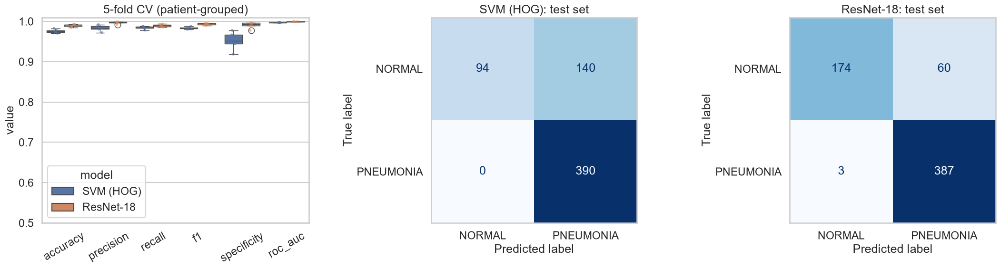

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
cv_long = pd.concat([svm_cv.assign(model="SVM (HOG)"), cnn_cv.assign(model="ResNet-18")]) \
            .melt(id_vars=["model", "fold"], value_vars=METRICS, var_name="metric")
sns.boxplot(data=cv_long, x="metric", y="value", hue="model", palette=PALETTE, ax=axes[0])
sns.stripplot(data=cv_long, x="metric", y="value", hue="model", palette=PALETTE, dodge=True, ax=axes[0],
              color="k", size=4, legend=False, alpha=.6)
axes[0].set(title="5-fold CV (patient-grouped)", xlabel="", ylim=(0.5, 1.01)); axes[0].tick_params(axis="x", rotation=30)
for ax, (name, p) in zip(axes[1:], p_test.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p >= .5).astype(int)), display_labels=CLASSES) \
        .plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}: test set"); ax.grid(False)
plt.tight_layout(); savefig("comparison_cv_confusion"); plt.show()

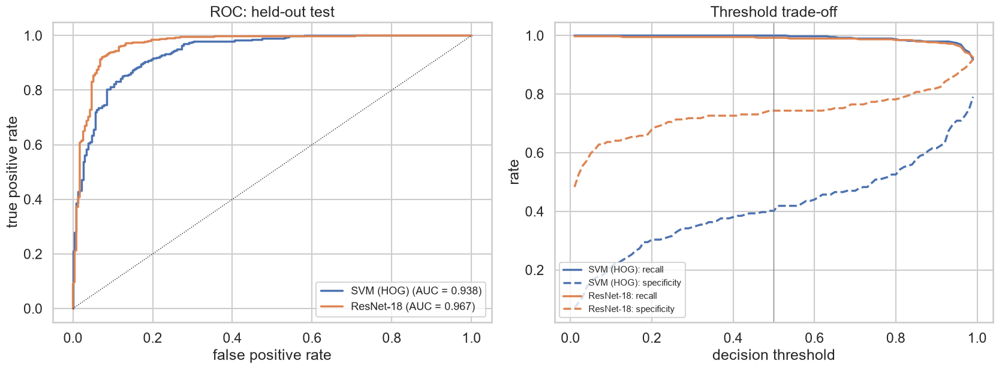

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for name, p in p_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2.5, color=PALETTE[name], label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    ths = np.linspace(0.01, 0.99, 99)
    axes[1].plot(ths, [recall_score(y_test, p >= t) for t in ths], color=PALETTE[name], lw=2.5, label=f"{name}: recall")
    axes[1].plot(ths, [recall_score(1 - y_test, p < t) for t in ths], color=PALETTE[name], lw=2.5, ls="--",
                 label=f"{name}: specificity")
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set(title="ROC: held-out test", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(loc="lower right", fontsize=13)
axes[1].axvline(.5, color="grey", lw=1); axes[1].set(title="Threshold trade-off", xlabel="decision threshold", ylabel="rate")
axes[1].legend(fontsize=11, loc="lower left")
plt.tight_layout(); savefig("roc_threshold"); plt.show()

**Interpretation: the gap between CV and test**
- In cross-validation both models look almost perfect (F1 ≈ 0.98–0.99, specificity ≈ 0.95–0.99). On the held-out test set,
  **recall stays near 1.0 but specificity collapses**: the SVM wrongly flags about 60 % of healthy children, the CNN about a quarter.
- Patient grouping rules out the obvious leakage *within* the training set, so the most likely explanation is a **distribution
  shift** between the training and test images: the test set was collected and graded separately, and the models treat its
  normal images differently from the training normals. (We cannot prove the cause from this data alone.) This is the strongest
  argument in this project for keeping an untouched test set: CV alone would have badly overstated real-world performance.
- ROC-AUC stays high (0.94–0.97), so the models still *rank* cases well. The problem is mainly **calibration and threshold**:
  healthy test images receive high scores. Raising the threshold trades recall for specificity (right-hand plot). A real deployment
  would set the threshold on a validation set from the *target* hospital.
- The ResNet-18 is better on every metric except recall, where both are essentially perfect (the SVM misses none of the
  390 pneumonia cases, the CNN one). McNemar's test shows the overall difference is statistically significant.

### 7.1 Practical trade-offs (deployment-relevant)

In [20]:
def latency_ms(fn, n=100):
    fn(); t0 = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t0) / n * 1000

one = test_idx[:1]
svm_lat = latency_ms(lambda: svm_final.predict_proba(classical_features(X_all[one])))
cnn_lat = latency_ms(lambda: (predict_proba_cnn(cnn_final, one), torch.cuda.synchronize() if DEVICE.type == "cuda" else None))
# CPU latency matters for deployment: can the CNN be served without a GPU?
cnn_cpu = copy.deepcopy(cnn_final).cpu().eval()
x_cpu = to_input(X_gpu[torch.as_tensor(one, device=DEVICE)]).cpu()
with torch.no_grad():
    cnn_cpu_lat = latency_ms(lambda: cnn_cpu(x_cpu), n=30)
del cnn_cpu
svm_bytes = len(pickle.dumps(svm_final))
cnn_bytes = (MODEL_DIR / "resnet18_pneumonia.pt").stat().st_size
tradeoffs = pd.DataFrame({
    "SVM (HOG)": {"test F1": test_table.loc["SVM (HOG)", "f1"], "test recall": test_table.loc["SVM (HOG)", "recall"],
                  "test AUC": test_table.loc["SVM (HOG)", "roc_auc"],
                  # feature extraction timed over all images; count only the training share
                  "final training time (s)": round(svm_train_time + feat_time * len(train_idx) / len(X_all), 1),
                  "inference latency (ms/image)": f"{svm_lat:.1f} (CPU)", "model size (MB)": round(svm_bytes / 1e6, 1),
                  "hardware needed": "CPU",
                  "trainable parameters": f"{svm_final.named_steps['svm'].n_support_.sum()} support vectors × "
                                          f"{svm_final.named_steps['pca'].n_components_} PCA dims"},
    "ResNet-18": {"test F1": test_table.loc["ResNet-18", "f1"], "test recall": test_table.loc["ResNet-18", "recall"],
                  "test AUC": test_table.loc["ResNet-18", "roc_auc"],
                  "final training time (s)": round(cnn_train_time, 1),
                  "inference latency (ms/image)": f"{cnn_lat:.1f} (GPU) / {cnn_cpu_lat:.0f} (CPU)", "model size (MB)": round(cnn_bytes / 1e6, 1),
                  "hardware needed": "GPU (training); CPU ok for inference",
                  "trainable parameters": f"{sum(p.numel() for p in cnn_final.parameters())/1e6:.1f}M"}})
tradeoffs

,SVM (HOG),ResNet-18
test F1,0.847826,0.924731
test recall,1.0,0.992308
test AUC,0.938264,0.966913
final training time (s),13.8,26.3
inference latency (ms/image),3.1 (CPU),2.2 (GPU) / 13 (CPU)
model size (MB),7.4,44.8
hardware needed,CPU,GPU (training); CPU ok for inference
trainable parameters,1116 support vectors × 455 PCA dims,11.2M


### 7.2 Comparison with published approaches on the same test set
The dataset authors and later studies report results on the **same 624-image test set**, so we can place our two models in context.
Published figures are as reported (Kermany et al., 2018, as tabulated by Rajaraman et al., 2018, Table 4).

Our AUC is close to the published CNNs, so the *ranking* of cases is comparable; the difference is mainly the **operating point**
(our models sit at near-100 % sensitivity with low specificity). To illustrate, we also report our models' specificity at the
sensitivity Kermany et al. reported. *This threshold is picked on the test set, so it is an illustration, not a valid result.*

In [21]:
published = pd.DataFrame([
    {"approach": "Kermany et al. 2018: Inception-v3, transfer learning", "accuracy": .928, "recall": .932, "specificity": .901, "roc_auc": .968},
    {"approach": "Rajaraman et al. 2018: VGG16, cropped to lung region", "accuracy": .962, "recall": .962, "specificity": .962, "roc_auc": .993},
])
ours = test_table[["accuracy", "recall", "specificity", "roc_auc"]].rename(index=lambda n: f"This work: {n} (threshold 0.5)")
KERMANY_SENS = 0.932
def specificity_at_sensitivity(y, prob, target):
    fpr, tpr, thr = roc_curve(y, prob)
    i = np.argmax(tpr >= target)
    return 1 - fpr[i], thr[i]
illustr = {f"This work: {n} at sensitivity {KERMANY_SENS} (illustrative)":
           dict(zip(["specificity", "threshold"], specificity_at_sensitivity(y_test, p, KERMANY_SENS))) for n, p in p_test.items()}
literature_table = pd.concat([published.set_index("approach"), ours, pd.DataFrame(illustr).T])
literature_table.round(3)

,accuracy,recall,specificity,roc_auc,threshold
"Kermany et al. 2018: Inception-v3, transfer learning",0.928,0.932,0.901,0.968,NaN
"Rajaraman et al. 2018: VGG16, cropped to lung region",0.962,0.962,0.962,0.993,NaN
This work: SVM (HOG) (threshold 0.5),0.776,1.000,0.402,0.938,NaN
This work: ResNet-18 (threshold 0.5),0.899,0.992,0.744,0.967,NaN
This work: SVM (HOG) at sensitivity 0.932 (illustrative),NaN,NaN,0.769,NaN,0.987
This work: ResNet-18 at sensitivity 0.932 (illustrative),NaN,NaN,0.910,NaN,0.985


## 8. Explainability

We use two complementary methods:
- **Grad-CAM** (CNN only) weights the final convolutional feature maps by the gradient of the pneumonia logit.
  The heatmap shows *where* the network gathered evidence.
- **LIME** (model-agnostic) segments the image into superpixels, perturbs them by greying them out, and fits a local linear surrogate.
  We apply it to **both** models on the same images, so we can compare *what each model relies on*.

We also check quantitatively for **shortcut learning**: what fraction of the Grad-CAM attention falls *outside* the central
thoracic region, i.e. on borders, text markers and the abdomen?

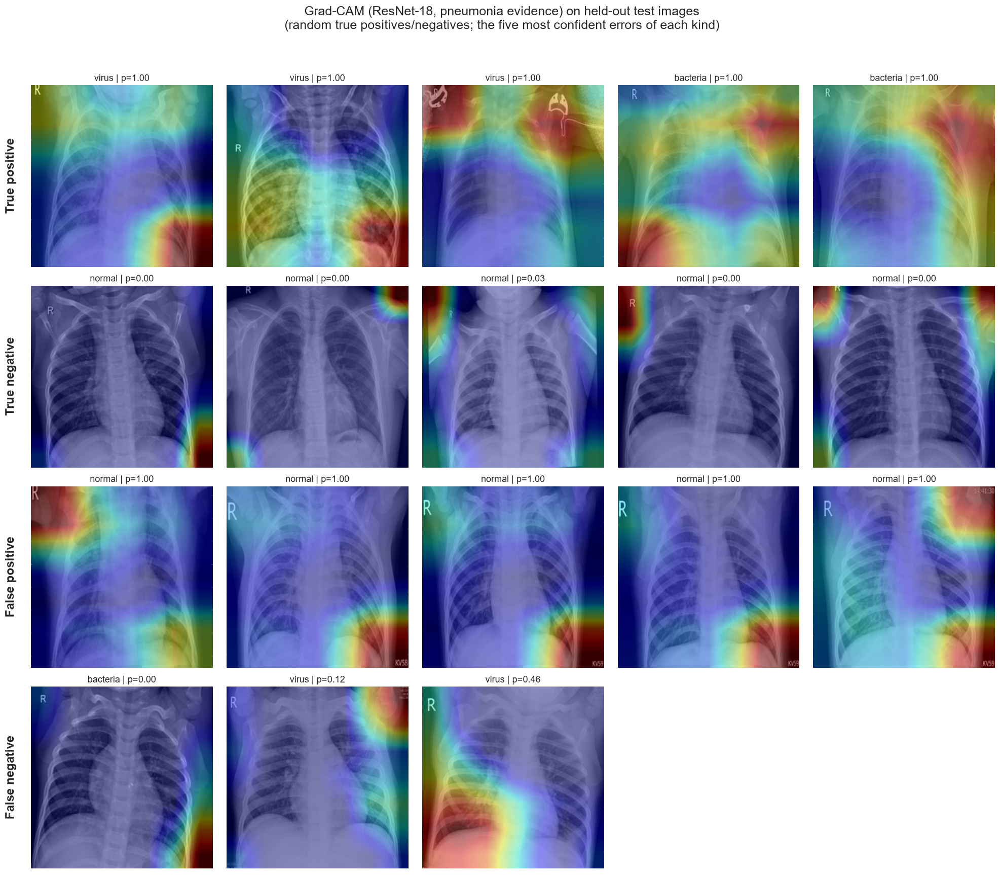

In [22]:
cnn_final.eval()
cam_extractor = GradCAM(model=cnn_final, target_layers=[cnn_final.layer4[-1]])

def gradcam(idx_list, target=1):
    xb = to_input(X_gpu[torch.as_tensor(idx_list, device=DEVICE)])
    return cam_extractor(input_tensor=xb, targets=[ClassifierOutputTarget(target)] * len(idx_list))

def overlay(ax, img, cam, title):
    ax.imshow(img, cmap="gray"); ax.imshow(cam, cmap="jet", alpha=.4); ax.axis("off"); ax.set_title(title, fontsize=13)

pred_cnn = (p_test["ResNet-18"] >= .5).astype(int)
groups = {"True positive": (y_test == 1) & (pred_cnn == 1), "True negative": (y_test == 0) & (pred_cnn == 0),
          "False positive": (y_test == 0) & (pred_cnn == 1), "False negative": (y_test == 1) & (pred_cnn == 0)}
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(4, 5, figsize=(20, 17))
for row, (gname, mask) in zip(axes, groups.items()):
    pos = np.where(mask)[0]
    if gname.startswith("False"):
        # errors: show the most confident ones (highest p for false positives, lowest p for false negatives)
        order = np.argsort(p_test["ResNet-18"][pos])
        chosen = pos[order[::-1][:5]] if gname == "False positive" else pos[order[:5]]
    else:
        chosen = rng.choice(pos, size=min(5, len(pos)), replace=False) if len(pos) else []
    cams = gradcam(test_idx[chosen]) if len(chosen) else []
    for ax in row: ax.axis("off")
    for ax, i, cam in zip(row, chosen, cams):
        overlay(ax, X_all[test_idx[i]], cam, f"{meta.subtype.iloc[test_idx[i]]} | p={p_test['ResNet-18'][i]:.2f}")
    row[0].text(-0.08, 0.5, gname, transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=17, fontweight="bold")
plt.suptitle("Grad-CAM (ResNet-18, pneumonia evidence) on held-out test images\n"
             "(random true positives/negatives; the five most confident errors of each kind)", fontsize=18, y=1.02)
plt.tight_layout(); savefig("gradcam_grid"); plt.show()

Predicted-pneumonia images: 447 (of which false positives: 60)
Mean Grad-CAM mass outside central region: 42.3% (uniform baseline 36.1%)
  false positives only: 45.6% | true positives only: 41.8%
Flagged images with >50 % of attention outside: 4.5%


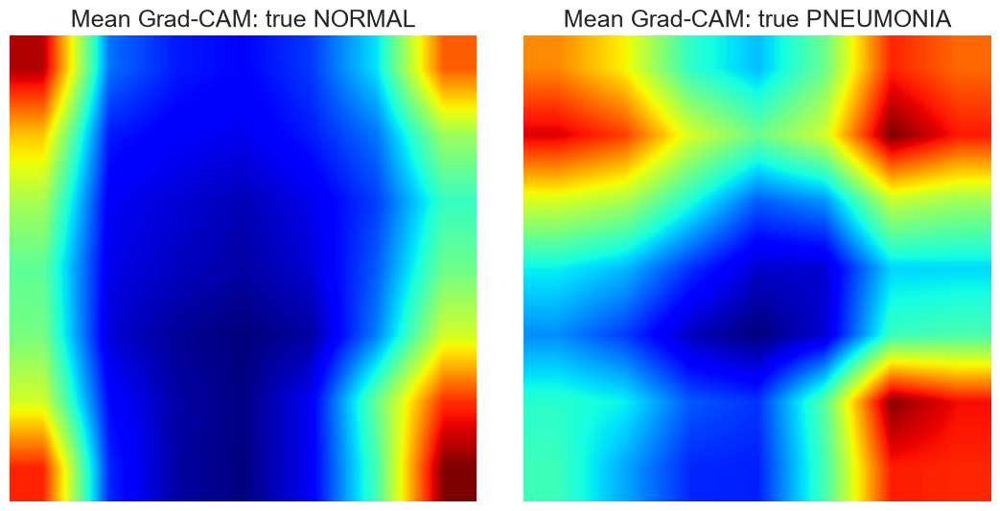

In [23]:
# Shortcut check: share of Grad-CAM mass outside a central thoracic box (rows 10–90 %, cols 10–90 %).
# Measured on images the CNN *predicts* as pneumonia, where the pneumonia heatmap is the evidence behind a real decision
# (for confident negatives the pneumonia CAM is near zero and its per-image normalisation makes the map meaningless).
cams_all = np.concatenate([gradcam(test_idx[i:i + 64]) for i in range(0, len(test_idx), 64)])
cam_extractor.activations_and_grads.release()   # remove hooks so later forward passes don't store activations
H = W = IMG_SIZE
inner = np.zeros((H, W), bool); inner[int(.1 * H):int(.9 * H), int(.1 * W):int(.9 * W)] = True
outside_frac = (cams_all * ~inner).sum((1, 2)) / (cams_all.sum((1, 2)) + 1e-8)
baseline = 1 - inner.mean()   # share expected if attention were spread uniformly
flagged = pred_cnn == 1
print(f"Predicted-pneumonia images: {flagged.sum()} (of which false positives: {(flagged & (y_test == 0)).sum()})")
print(f"Mean Grad-CAM mass outside central region: {outside_frac[flagged].mean():.1%} (uniform baseline {baseline:.1%})")
print(f"  false positives only: {outside_frac[flagged & (y_test == 0)].mean():.1%} | true positives only: "
      f"{outside_frac[flagged & (y_test == 1)].mean():.1%}")
print(f"Flagged images with >50 % of attention outside: {(outside_frac[flagged] > .5).mean():.1%}")
mean_cam = pd.DataFrame({"cam": list(cams_all), "label": y_test})
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (lab, g) in zip(axes, mean_cam.groupby("label")):
    ax.imshow(np.mean(np.stack(g.cam), 0), cmap="jet"); ax.axis("off")
    ax.set_title(f"Mean Grad-CAM: true {CLASSES[lab]}")
plt.tight_layout(); savefig("gradcam_mean"); plt.show()

**What Grad-CAM reveals**
- The **mean** heatmaps show the CNN's pneumonia evidence leaning towards the **corners and edges** of the image (shoulders, the "R"
  side-marker region, bottom-right corner) rather than the lung fields. On images it flags as pneumonia, more of its attention falls
  outside the central region than a uniform map would put there (printed above). Most attention is still central, so this is a bias, not total failure.
- The CNN's **five most confident false positives** (healthy children scored near 100 %) all light up burnt-in text: the
  "KV58"/"KV59" exposure label in the bottom-right corner, a timestamp, or the "R" side marker.
  This is consistent with **shortcut learning** (Geirhos et al., 2020): features that separate the classes in this dataset but are
  not pathology. Similar shortcuts have been reported for chest X-ray models before, e.g. hospital-specific markers (Zech et al., 2018)
  and laterality tokens and image borders in COVID-19 classifiers (DeGrave et al., 2021).
- Some true positives *do* highlight lung opacities, so the model mixes genuine and spurious evidence. Grad-CAM is coarse (7×7 grid
  upsampled), so these maps show the general region of evidence, not exact pixels.

**LIME comparison (below):** LIME greys out superpixels and measures the change in prediction, so it treats both models the same way.
For both models the most influential superpixels often include **background, the image border and the abdomen**, not only the lungs.
The SVM's HOG features respond to strong edges anywhere in the image, so it has no built-in notion of "lungs" at all. LIME explanations
also vary from run to run (random perturbations), so we read them qualitatively and alongside Grad-CAM.

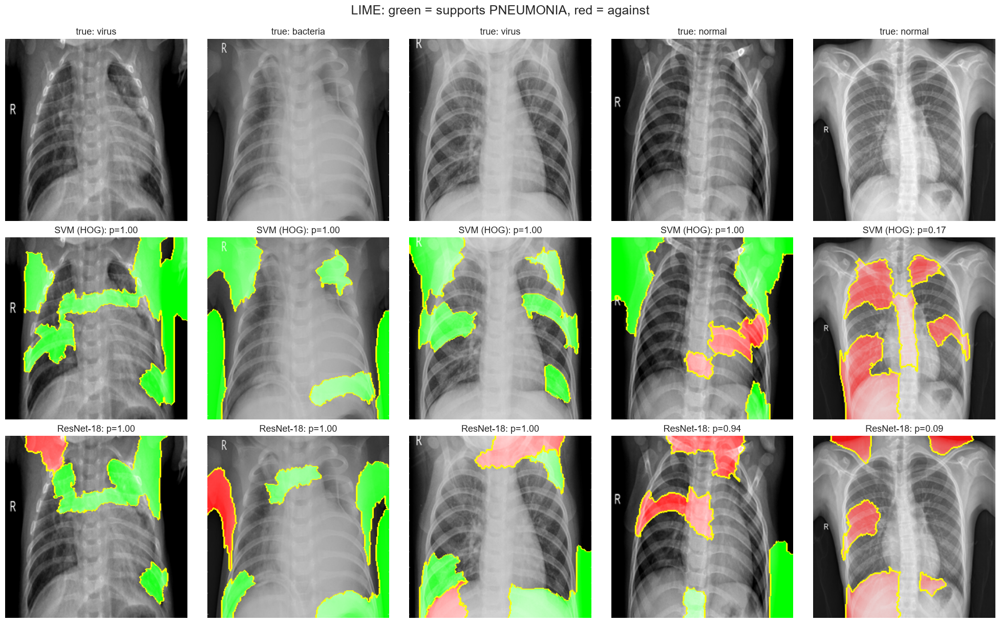

In [24]:
def lime_to_grey_u8(batch_rgb) -> np.ndarray:
    """LIME passes (N, H, W, 3) copies of our uint8 image with some superpixels greyed out; take one channel as uint8."""
    grey = np.asarray(batch_rgb)[..., 0]
    return grey if grey.dtype == np.uint8 else np.clip(np.round(grey), 0, 255).astype(np.uint8)

def svm_predict_rgb(batch_rgb):
    return svm_final.predict_proba(classical_features(lime_to_grey_u8(batch_rgb)))

@torch.no_grad()
def cnn_predict_rgb(batch_rgb):
    x = torch.from_numpy(lime_to_grey_u8(batch_rgb).astype(np.float32) / 255).to(DEVICE).unsqueeze(1)
    cnn_final.eval()
    with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
        return torch.softmax(cnn_final(normalise(x)).float(), 1).cpu().numpy()

lime_image.tqdm = lambda it, **kw: it   # lime 0.2 has no switch for its per-call progress bar; silence it
explainer = lime_image.LimeImageExplainer(random_state=SEED)
rng = np.random.default_rng(SEED)
lime_examples = np.concatenate([rng.choice(np.where((y_test == 1))[0], 3, replace=False),
                                rng.choice(np.where((y_test == 0))[0], 2, replace=False)])
fig, axes = plt.subplots(3, len(lime_examples), figsize=(4 * len(lime_examples), 12.5))
for j, i in enumerate(lime_examples):
    img = X_all[test_idx[i]]
    rgb = np.stack([img] * 3, -1)
    axes[0, j].imshow(img, cmap="gray"); axes[0, j].set_title(f"true: {meta.subtype.iloc[test_idx[i]]}", fontsize=13)
    for r, (name, fn) in enumerate([("SVM (HOG)", svm_predict_rgb), ("ResNet-18", cnn_predict_rgb)], start=1):
        exp = explainer.explain_instance(rgb, fn, labels=(1,), top_labels=None, hide_color=128, num_samples=600, random_seed=SEED)
        tmp, mask = exp.get_image_and_mask(1, positive_only=False, num_features=6, hide_rest=False)
        axes[r, j].imshow(mark_boundaries(tmp / 255.0, mask))
        axes[r, j].set_title(f"{name}: p={fn(rgb[None])[0, 1]:.2f}", fontsize=13)
    for ax in axes[:, j]: ax.axis("off")
plt.suptitle("LIME: green = supports PNEUMONIA, red = against", fontsize=18)
plt.tight_layout(); savefig("lime_comparison"); plt.show()

## 9. Bias and diagnostic analysis

Performance overall can hide disparities between groups. We look at three:
1. **Pneumonia subtype (bacterial vs viral).** Viral pneumonia tends to look more diffuse and subtle on X-ray. Is it missed more often?
2. **Image brightness quartiles** (mean pixel intensity). This is a proxy for exposure settings and scanner or acquisition differences.
3. **Image contrast quartiles** (pixel standard deviation).
4. **Acquisition batch** (normal images only). Normal filenames come in two families, `IM-…` and `NORMAL2-IM-…`, which look
   like separate collection batches. The test set has proportionally more `NORMAL2` images than the training set.

Quartile edges come from the training set. We then run a **robustness stress test**: a gamma transform simulates
under- and over-exposed acquisitions, a likely shift when a model is deployed to another hospital.

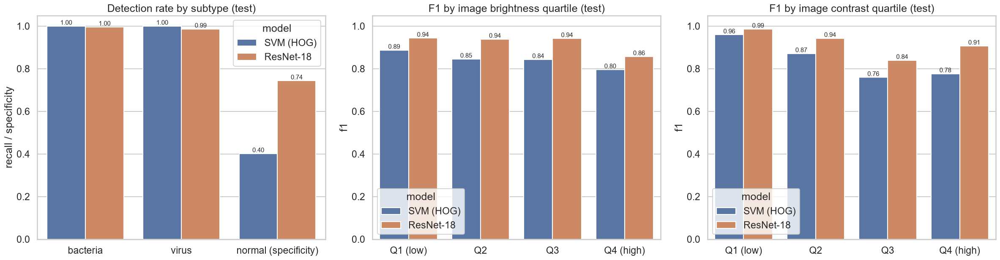

,model,attribute,quartile,n,% pneumonia,f1,recall,specificity,FN,FP
0,SVM (HOG),brightness,Q1 (low),181,69.613,0.887,1.000,0.418,0,32
1,SVM (HOG),brightness,Q2,151,61.589,0.845,1.000,0.414,0,34
2,SVM (HOG),brightness,Q3,158,61.392,0.843,1.000,0.410,0,36
3,SVM (HOG),brightness,Q4 (high),134,55.224,0.796,1.000,0.367,0,38
4,SVM (HOG),contrast,Q1 (low),124,85.484,0.959,1.000,0.500,0,9
5,SVM (HOG),contrast,Q2,188,70.213,0.871,1.000,0.304,0,39
6,SVM (HOG),contrast,Q3,166,47.590,0.760,1.000,0.425,0,50
7,SVM (HOG),contrast,Q4 (high),146,50.000,0.777,1.000,0.425,0,42
8,ResNet-18,brightness,Q1 (low),181,69.613,0.944,1.000,0.727,0,15
9,ResNet-18,brightness,Q2,151,61.589,0.939,0.989,0.810,1,11


In [25]:
test_meta = meta.iloc[test_idx].reset_index(drop=True).copy()
for c in ("brightness", "contrast"):
    edges = np.quantile(meta.iloc[train_idx][c], [0, .25, .5, .75, 1]); edges[0], edges[-1] = -np.inf, np.inf
    test_meta[f"{c}_q"] = pd.cut(test_meta[c], edges, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])

rows = []
for name, p in p_test.items():
    pred = (p >= .5).astype(int)
    for sub in ("bacteria", "virus"):
        mask = (test_meta.subtype == sub).values
        rows.append({"model": name, "group": "subtype", "level": sub, "n": mask.sum(), "recall": recall_score(y_test[mask], pred[mask])})
    mask = (test_meta.subtype == "normal").values
    rows.append({"model": name, "group": "subtype", "level": "normal (specificity)", "n": mask.sum(),
                 "recall": (pred[mask] == 0).mean()})
subtype_df = pd.DataFrame(rows)

q_rows = []
for name, p in p_test.items():
    for c in ("brightness_q", "contrast_q"):
        for lvl, g in test_meta.groupby(c, observed=True):
            idx = g.index.values
            q_rows.append({"model": name, "attribute": c.replace("_q", ""), "quartile": lvl, "n": len(idx),
                           "% pneumonia": 100 * y_test[idx].mean(), **compute_metrics(y_test[idx], p[idx])})
quart_df = pd.DataFrame(q_rows)

fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
sns.barplot(data=subtype_df, x="level", y="recall", hue="model", palette=PALETTE, ax=axes[0])
axes[0].set(title="Detection rate by subtype (test)", xlabel="", ylabel="recall / specificity", ylim=(0, 1.05))
for cont in axes[0].containers: axes[0].bar_label(cont, fmt="%.2f", fontsize=11)
for ax, attr in zip(axes[1:], ("brightness", "contrast")):
    d = quart_df.query("attribute==@attr")
    sns.barplot(data=d, x="quartile", y="f1", hue="model", palette=PALETTE, ax=ax)
    ax.set(title=f"F1 by image {attr} quartile (test)", xlabel="", ylim=(0, 1.05))
    for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=11)
plt.tight_layout(); savefig("bias_subgroups"); plt.show()
quart_df[["model", "attribute", "quartile", "n", "% pneumonia", "f1", "recall", "specificity", "FN", "FP"]].round(3)

**Reading this carefully:** subgroups also differ in their *class mix* (`% pneumonia`), and that alone shifts precision and F1.
Recall and specificity within each group are the fairer comparison. Subgroups are small (e.g. 148 viral cases, ~55–65 normal
images per brightness quartile), so we attach **exact (Clopper–Pearson) 95 % confidence intervals**. Unlike a bootstrap, these
remain informative when a rate is exactly 100 %.

In [26]:
def rate_ci(successes, n):
    """Exact binomial 95 % CI for a proportion (works at 0 % and 100 %)."""
    ci = binomtest(int(successes), int(n)).proportion_ci(confidence_level=0.95, method="exact")
    return ci.low, ci.high

ci_rows = []
for name, p in p_test.items():
    pred = (p >= .5).astype(int)
    for sub in ("bacteria", "virus", "normal"):
        mask = (test_meta.subtype == sub).values
        correct = (pred[mask] == y_test[mask]).sum()          # recall for pneumonia subtypes, specificity for normal
        lo, hi = rate_ci(correct, mask.sum())
        ci_rows.append({"model": name, "group": sub, "metric": "specificity" if sub == "normal" else "recall",
                        "n": mask.sum(), "rate": correct / mask.sum(), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
    for b, g in test_meta[test_meta.subtype == "normal"].groupby("batch"):
        correct = (pred[g.index.values] == 0).sum()
        lo, hi = rate_ci(correct, len(g))
        ci_rows.append({"model": name, "group": f"normal, batch {b}", "metric": "specificity",
                        "n": len(g), "rate": correct / len(g), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
    for q, g in test_meta[test_meta.subtype == "normal"].groupby("brightness_q", observed=True):
        correct = (pred[g.index.values] == 0).sum()
        lo, hi = rate_ci(correct, len(g))
        ci_rows.append({"model": name, "group": f"normal, brightness {q}", "metric": "specificity",
                        "n": len(g), "rate": correct / len(g), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
subgroup_ci = pd.DataFrame(ci_rows)
print("Share of NORMAL2 among normal images:",
      meta[meta.subtype == "normal"].groupby("split").batch.apply(lambda b: f"{(b == 'NORMAL2').mean():.0%}").to_dict())
subgroup_ci.round(3)

Share of NORMAL2 among normal images: {'test': '71%', 'train': '56%'}


,model,group,metric,n,rate,95% CI
0,SVM (HOG),bacteria,recall,242,1.000,"[0.985, 1.000]"
1,SVM (HOG),virus,recall,148,1.000,"[0.975, 1.000]"
2,SVM (HOG),normal,specificity,234,0.402,"[0.338, 0.468]"
3,SVM (HOG),"normal, batch IM",specificity,69,0.464,"[0.343, 0.588]"
4,SVM (HOG),"normal, batch NORMAL2",specificity,165,0.376,"[0.302, 0.454]"
5,SVM (HOG),"normal, brightness Q1 (low)",specificity,55,0.418,"[0.287, 0.559]"
6,SVM (HOG),"normal, brightness Q2",specificity,58,0.414,"[0.286, 0.551]"
7,SVM (HOG),"normal, brightness Q3",specificity,61,0.410,"[0.286, 0.543]"
8,SVM (HOG),"normal, brightness Q4 (high)",specificity,60,0.367,"[0.246, 0.501]"
9,ResNet-18,bacteria,recall,242,0.996,"[0.977, 1.000]"


gamma:   0%|          | 0/7 [00:00<?, ?it/s]

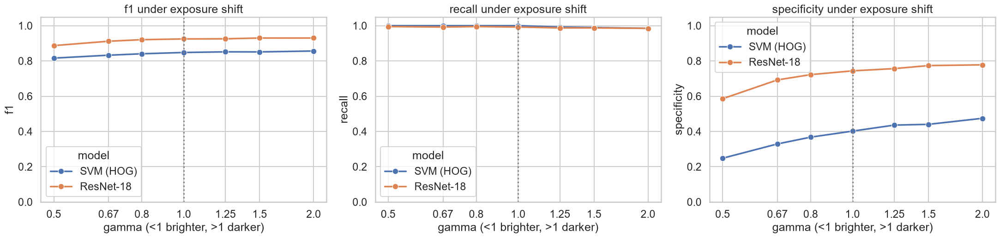

In [27]:
# Robustness stress test: simulate exposure shift with a gamma transform applied to the raw test images.
# Predictors take a uint8 image array, so the same function also tests the mitigated models in Section 10.
def predict_svm_imgs(model, imgs_u8):
    return model.predict_proba(classical_features(imgs_u8))[:, 1]

def predict_cnn_imgs(model, imgs_u8):
    return predict_proba_cnn(model, np.arange(len(imgs_u8)), X=torch.from_numpy(imgs_u8).to(DEVICE))

GAMMAS = [0.5, 0.67, 0.8, 1.0, 1.25, 1.5, 2.0]
def gamma_stress(predictors, imgs_u8, y):
    out = []
    for g in tqdm(GAMMAS, desc="gamma"):
        shifted = (255 * (imgs_u8 / 255.0) ** g).round().astype(np.uint8)
        for name, fn in predictors.items():
            out.append({"gamma": g, "model": name, **compute_metrics(y, fn(shifted))})
    return pd.DataFrame(out)

def plot_stress(df, name, palette=PALETTE):
    fig, axes = plt.subplots(1, 3, figsize=(22, 5.5))
    for ax, met in zip(axes, ("f1", "recall", "specificity")):
        sns.lineplot(data=df, x="gamma", y=met, hue="model", palette=palette, marker="o", lw=2.5, ax=ax)
        ax.axvline(1, color="grey", ls=":"); ax.set_xscale("log"); ax.set_xticks(GAMMAS, [str(g) for g in GAMMAS])
        ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
        ax.set(title=f"{met} under exposure shift", xlabel="gamma (<1 brighter, >1 darker)", ylim=(0, 1.05))
    plt.tight_layout(); savefig(name); plt.show()

stress_df = gamma_stress({"SVM (HOG)": lambda im: predict_svm_imgs(svm_final, im),
                          "ResNet-18": lambda im: predict_cnn_imgs(cnn_final, im)}, X_all[test_idx], y_test)
plot_stress(stress_df, "robustness_gamma")

**Findings of the bias analysis**
- **Pneumonia subtype:** no detectable gap. Both bacterial and viral cases are detected almost perfectly, and the exact
  confidence intervals overlap. The disparity is *between classes*: healthy children carry almost all the errors (false positives).
- **Brightness:** in the quartile analysis specificity tends to be lowest for the brightest images, but with ~60 normal images
  per quartile the confidence intervals overlap, so on its own this is weak evidence. The **stress test** is clearer: making
  the same test images brighter (gamma < 1) pushes specificity down for both models, and darker images raise it. Pneumonia
  appears as *whiter* lungs, which suggests both models have partly learned "brighter = pneumonia". Both lose a similar amount
  of specificity in absolute terms, but relative to its starting point the SVM (whose features include a raw intensity
  histogram) loses far more, and the CNN stays well ahead of it at every exposure level.
- **Contrast:** F1 varies across quartiles, but these groups also differ strongly in class mix (`% pneumonia`), so the specificity
  column is the fairer comparison.
- **Acquisition batch:** both models clear fewer healthy children from the `NORMAL2` batch than from the `IM` batch (table above),
  but with 69 `IM` normals the confidence intervals overlap, so this is a **trend, not an established gap**. The test set contains
  proportionally more `NORMAL2` normals than training, which may explain part of the CV-to-test drop and is worth testing with more data.
- **Real-world meaning:** a hospital whose images are brighter than this training data (for example, different or poorly
  calibrated equipment or exposure protocols) could see noticeably more healthy children flagged. The harm would fall unevenly across sites.

## 10. Mitigation experiment: can we remove the shortcut?

Sections 7–9 show that both models clear far fewer healthy children on the test set than in cross-validation, and that
Grad-CAM attention often sits on image corners and burnt-in text rather than on the lungs. We test one targeted fix,
**changing only the input** (the CNN keeps every hyperparameter; the SVM's `C`/`gamma` are re-tuned on the new features with the
same grid and folds, because its features change), so any change can be attributed to the preprocessing:

1. **Border crop (10 % per side), then resize back to 224×224.** This removes most corner text ("R", "KV59", timestamps),
   collimator edges and the shoulders and abdomen, while keeping the lung fields.
2. **CLAHE** (contrast-limited adaptive histogram equalisation, clip limit 2.0, 8×8 tiles). This standardises exposure and contrast
   between machines, targeting the brightness disparity seen in Section 9.

Both models are re-run on the **same patient-grouped folds** and evaluated on the same held-out test set.

*Status: exploratory.* This experiment was designed **after** looking at test-set Grad-CAM maps, so its test results are not an
untouched estimate; they show whether the fix helps, not how well it would work at a new hospital.

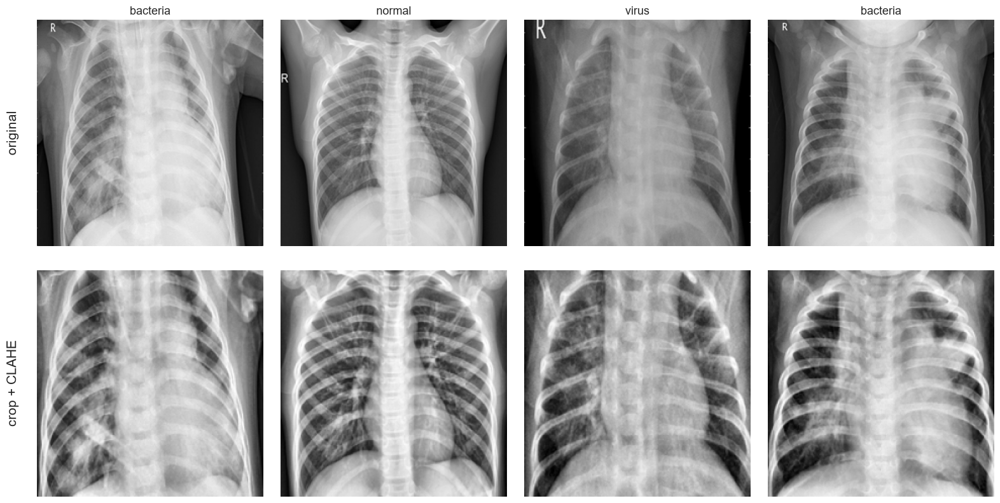

In [28]:
CROP = 0.10
def mitigate(imgs_u8: np.ndarray) -> np.ndarray:
    c = int(round(CROP * IMG_SIZE))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return np.stack([clahe.apply(cv2.resize(np.ascontiguousarray(im[c:-c, c:-c]), (IMG_SIZE, IMG_SIZE),
                                            interpolation=cv2.INTER_AREA)) for im in imgs_u8])

X_mit = mitigate(X_all)
X_mit_gpu = torch.from_numpy(X_mit).to(DEVICE)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for j, i in enumerate(rng.choice(test_idx, 4, replace=False)):
    axes[0, j].imshow(X_all[i], cmap="gray"); axes[1, j].imshow(X_mit[i], cmap="gray")
    axes[0, j].set_title(meta.subtype.iloc[i], fontsize=13)
for ax in axes.ravel(): ax.axis("off")
axes[0, 0].text(-0.08, .5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", fontsize=15)
axes[1, 0].text(-0.08, .5, "crop + CLAHE", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", fontsize=15)
plt.tight_layout(); savefig("mitigation_examples"); plt.show()

In [29]:
# Classical model on mitigated images: features change, so C/gamma are re-tuned with the same grid and folds
F_mit = classical_features(X_mit)
grid_mit = GridSearchCV(svm_pipe, param_grid, cv=folds, scoring=scoring, refit=False, n_jobs=-1).fit(F_mit[train_idx], y_all[train_idx])
res_mit = pd.DataFrame(grid_mit.cv_results_)
best_params_mit = res_mit.loc[res_mit.rank_test_f1.idxmin()].params
print("Best SVM params on mitigated features:", best_params_mit)
svm_mit_cv = []
for k, (tr, va) in enumerate(folds):
    fold_model = clone(svm_pipe).set_params(**best_params_mit, svm__probability=True).fit(F_mit[train_idx][tr], y_all[train_idx][tr])
    svm_mit_cv.append({"fold": k, **compute_metrics(y_all[train_idx][va], fold_model.predict_proba(F_mit[train_idx][va])[:, 1])})
svm_mit_cv = pd.DataFrame(svm_mit_cv)
svm_mit = clone(svm_pipe).set_params(**best_params_mit, svm__probability=True).fit(F_mit[train_idx], y_all[train_idx])

# CNN on mitigated images (same architecture, schedule and seed)
cnn_mit_cv = []
for k, (tr, va) in enumerate(folds):
    model, hist = train_cnn(train_idx[tr], train_idx[va], verbose=False, X=X_mit_gpu)
    cnn_mit_cv.append({"fold": k, "best_epoch": int(hist.loc[hist.val_loss.idxmin(), "epoch"]),
                       **compute_metrics(y_all[train_idx][va], predict_proba_cnn(model, train_idx[va], X=X_mit_gpu))})
    del model; torch.cuda.empty_cache()
cnn_mit_cv = pd.DataFrame(cnn_mit_cv)
cnn_mit, _ = train_cnn(train_idx, None, epochs=int(np.median(cnn_mit_cv.best_epoch)), verbose=False, X=X_mit_gpu)
torch.save(cnn_mit.state_dict(), MODEL_DIR / "resnet18_pneumonia_mitigated.pt")

p_test_mit = {"SVM (HOG)": svm_mit.predict_proba(F_mit[test_idx])[:, 1],
              "ResNet-18": predict_proba_cnn(cnn_mit, test_idx, X=X_mit_gpu)}

rows = []
for variant, cvs, preds in (("baseline", {"SVM (HOG)": svm_cv, "ResNet-18": cnn_cv}, p_test),
                            ("crop + CLAHE", {"SVM (HOG)": svm_mit_cv, "ResNet-18": cnn_mit_cv}, p_test_mit)):
    for name in ("SVM (HOG)", "ResNet-18"):
        rows.append({"model": name, "input": variant, "CV F1": cvs[name].f1.mean(),
                     "CV specificity": cvs[name].specificity.mean(),
                     **{f"test {k}": v for k, v in compute_metrics(y_test, preds[name]).items()}})
mitigation_table = pd.DataFrame(rows).set_index(["model", "input"])
display(mitigation_table.round(3))

# Paired comparisons on the same test images
mcn_rows = []
for label, pa, pb in (("CNN: baseline vs crop + CLAHE", p_test["ResNet-18"], p_test_mit["ResNet-18"]),
                      ("Crop + CLAHE: SVM vs CNN", p_test_mit["SVM (HOG)"], p_test_mit["ResNet-18"]),
                      ("Baseline SVM vs crop + CLAHE CNN", p_test["SVM (HOG)"], p_test_mit["ResNet-18"])):
    only_a, only_b, pval = mcnemar_exact(y_test, pa >= .5, pb >= .5)
    mcn_rows.append({"comparison": label, "only first correct": only_a, "only second correct": only_b, "McNemar p": pval})
mcnemar_mit = pd.DataFrame(mcn_rows)
mcnemar_mit

Best SVM params on mitigated features: {'svm__C': 3, 'svm__gamma': 'scale'}


C:\Users\ali4l\AppData\Local\Temp\ipykernel_11624\1571701017.py:75: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


,,CV F1,CV specificity,test accuracy,test precision,test recall,test f1,test specificity,test roc_auc,test FN,test FP
model,input,,,,,,,,,,
SVM (HOG),baseline,0.984,0.952,0.776,0.736,1.000,0.848,0.402,0.938,0,140
ResNet-18,baseline,0.993,0.990,0.899,0.866,0.992,0.925,0.744,0.967,3,60
SVM (HOG),crop + CLAHE,0.980,0.945,0.777,0.739,0.995,0.848,0.415,0.923,2,137
ResNet-18,crop + CLAHE,0.990,0.985,0.853,0.810,0.997,0.894,0.611,0.968,1,91


,comparison,only first correct,only second correct,McNemar p
0,CNN: baseline vs crop + CLAHE,33,4,1.084394e-06
1,Crop + CLAHE: SVM vs CNN,6,53,1.753919e-10
2,Baseline SVM vs crop + CLAHE CNN,9,57,1.182785e-09


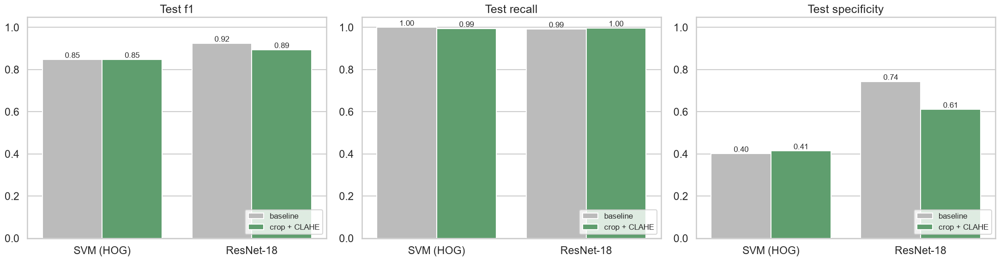

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
plot_df = mitigation_table.reset_index()
for ax, met in zip(axes, ("test f1", "test recall", "test specificity")):
    sns.barplot(data=plot_df, x="model", y=met, hue="input", palette=["#BBBBBB", "#55A868"], ax=ax)
    ax.set(title=met.replace("test ", "Test "), xlabel="", ylabel="", ylim=(0, 1.05))
    for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=12)
    ax.legend(fontsize=12, loc="lower right")
plt.tight_layout(); savefig("mitigation_results"); plt.show()

In [31]:
# Is the mitigated pipeline more robust to exposure shift? Same gamma stress test as Section 9, applied to the raw images
# *before* the crop + CLAHE preprocessing (as it would happen at a new hospital).
stress_mit_df = gamma_stress({"SVM (HOG)": lambda im: predict_svm_imgs(svm_mit, mitigate(im)),
                              "ResNet-18": lambda im: predict_cnn_imgs(cnn_mit, mitigate(im))}, X_all[test_idx], y_test)
stress_cmp = pd.concat([stress_df.assign(input="baseline"), stress_mit_df.assign(input="crop + CLAHE")])
display(stress_cmp.pivot_table(index=["model", "input"], columns="gamma", values="specificity").round(3))

gamma:   0%|          | 0/7 [00:00<?, ?it/s]

gamma                    0.50   0.67   0.80   1.00   1.25   1.50   2.00
model     input                                                        
ResNet-18 baseline      0.585  0.692  0.722  0.744  0.756  0.774  0.778
          crop + CLAHE  0.470  0.526  0.564  0.611  0.684  0.735  0.782
SVM (HOG) baseline      0.248  0.329  0.368  0.402  0.436  0.440  0.474
          crop + CLAHE  0.274  0.342  0.372  0.415  0.444  0.491  0.470

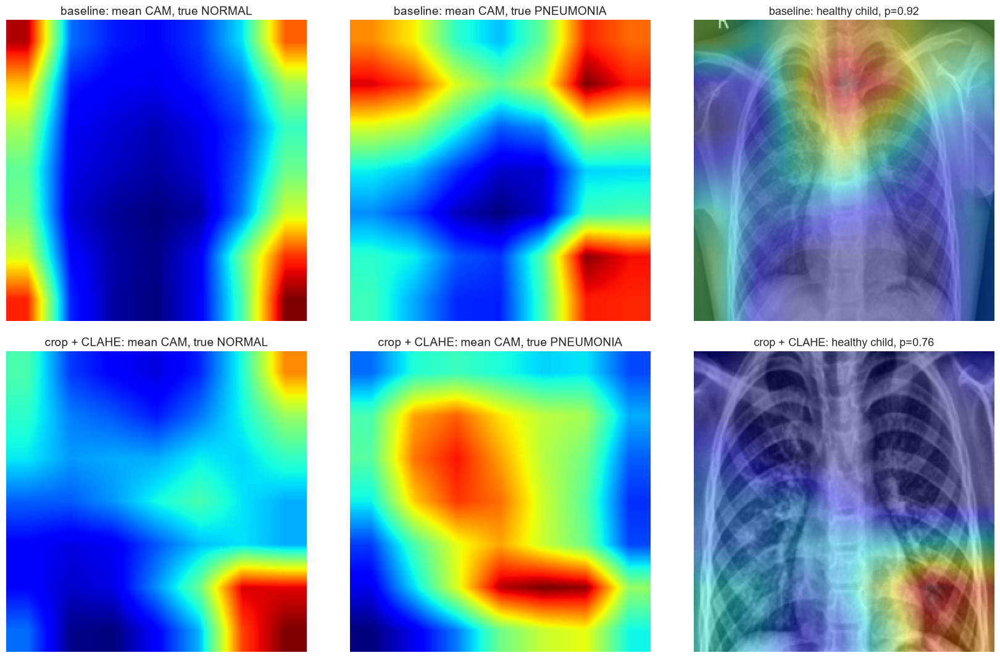

In [32]:
# Where does the mitigated CNN look? Mean Grad-CAM per true class, baseline vs mitigated
cam_mit_extractor = GradCAM(model=cnn_mit.eval(), target_layers=[cnn_mit.layer4[-1]])
cams_mit = np.concatenate([
    cam_mit_extractor(input_tensor=to_input(X_mit_gpu[torch.as_tensor(test_idx[i:i + 64], device=DEVICE)]),
                      targets=[ClassifierOutputTarget(1)] * len(test_idx[i:i + 64]))
    for i in range(0, len(test_idx), 64)])

cam_mit_extractor.activations_and_grads.release()
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
fp_example = np.where((y_test == 0) & (p_test["ResNet-18"] >= .5))[0]
ex = fp_example[0] if len(fp_example) else 0
for r, (label, cams, X_src, prob) in enumerate((("baseline", cams_all, X_all, p_test["ResNet-18"]),
                                                ("crop + CLAHE", cams_mit, X_mit, p_test_mit["ResNet-18"]))):
    for c, lab in enumerate((0, 1)):
        axes[r, c].imshow(np.mean(cams[y_test == lab], 0), cmap="jet"); axes[r, c].axis("off")
        axes[r, c].set_title(f"{label}: mean CAM, true {CLASSES[lab]}", fontsize=14)
    overlay(axes[r, 2], X_src[test_idx[ex]], cams[ex], f"{label}: healthy child, p={prob[ex]:.2f}")
plt.tight_layout(); savefig("mitigation_gradcam"); plt.show()

**What the mitigation experiment shows**
- **Attention moved towards the lungs.** After border cropping and CLAHE, the mean Grad-CAM for pneumonia cases sits over the
  lung fields instead of the corners. Individual maps are still imperfect (the example healthy child's heat sits low in the
  lung field, and the mean map for normal images still peaks at the edges).
- **False alarms got worse, not better.** The mitigated CNN clears *fewer* healthy children than the baseline CNN, and McNemar's
  test says the difference is significant (table above). The SVM barely changes.
- **No more robust to exposure.** CLAHE was meant to standardise exposure, but on brighter images the mitigated CNN loses about
  as much specificity as the baseline CNN, and ends lower.
- **Why might removing a shortcut hurt?** The held-out test set comes from the **same hospital**, so it shares the training
  images' burnt-in labels and framing: the shortcut genuinely *helps* on this test set. Cropping also discards some real
  anatomy, and CLAHE amplifies texture that may resemble opacities. A model without the shortcut could still generalise better
  to a new hospital, but this data cannot show that; only external validation can.
- **Lesson for XAI:** a *plausible* explanation is not proof of a *better* model. Grad-CAM helped us find a shortcut, but
  making the heatmaps look right made the measured performance worse.

## 11. Demo: single-image inference

This is the function a deployment API would wrap. It uses the **recommended model** (the baseline ResNet-18; see Section 12)
and returns the pneumonia probability, a triage decision, and a Grad-CAM overlay for the clinician to review.
The model is decision **support**, not an autonomous diagnosis. An interactive version for the recorded demo is in `demo/app.py`.

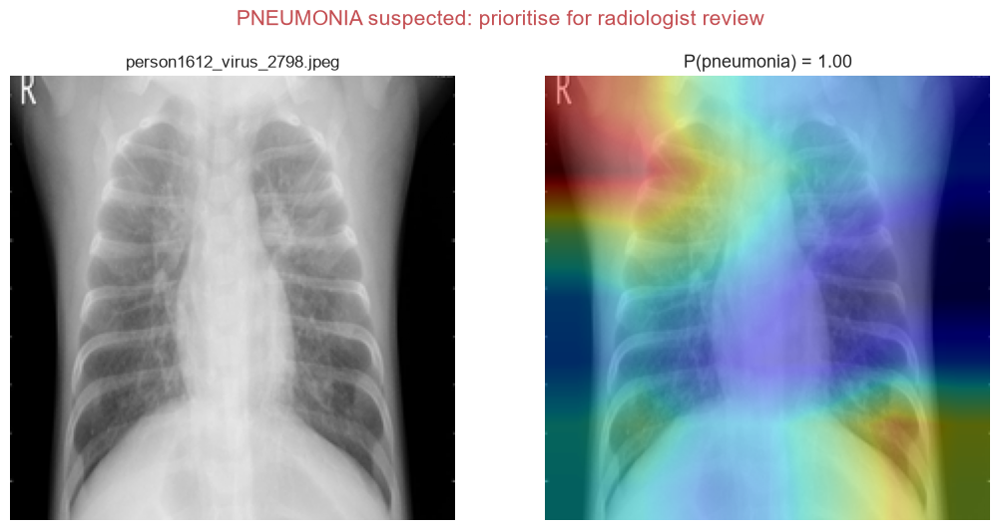

{'file': 'person1612_virus_2798.jpeg', 'p_pneumonia': 1.0, 'decision': 'PNEUMONIA suspected: prioritise for radiologist review'} | ground truth: virus


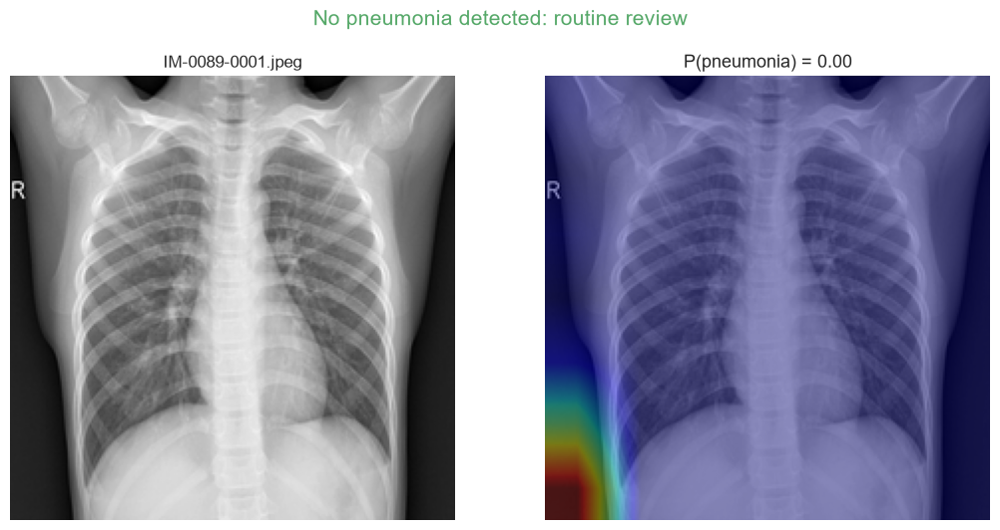

{'file': 'IM-0089-0001.jpeg', 'p_pneumonia': 0.0, 'decision': 'No pneumonia detected: routine review'} | ground truth: normal


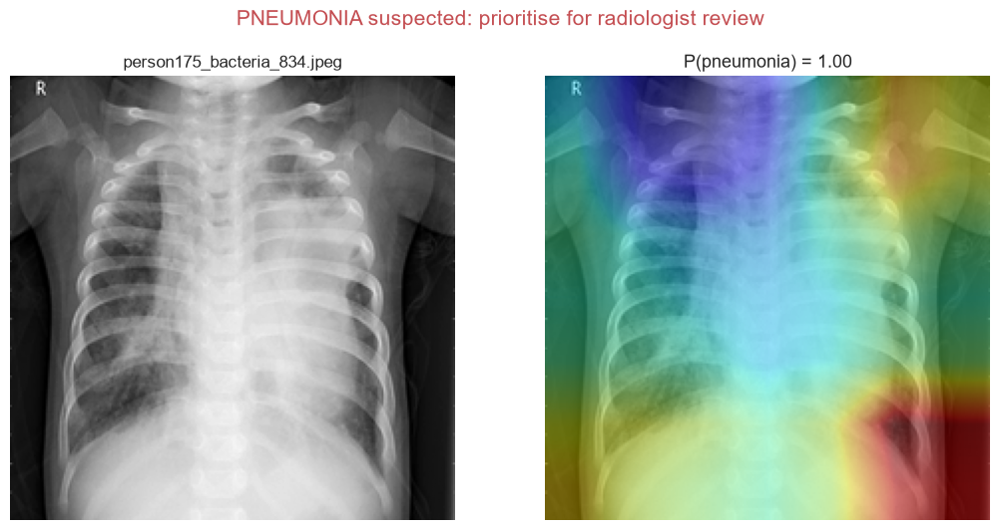

{'file': 'person175_bacteria_834.jpeg', 'p_pneumonia': 0.9998, 'decision': 'PNEUMONIA suspected: prioritise for radiologist review'} | ground truth: bacteria


In [33]:
def diagnose(image_path, threshold=0.5, show=True):
    img = np.asarray(Image.open(image_path).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.LANCZOS))
    x = to_input(torch.from_numpy(img).to(DEVICE)[None])   # same preprocessing as training
    cnn_final.eval()
    with torch.no_grad():
        prob = torch.softmax(cnn_final(x).float(), 1)[0, 1].item()
    with GradCAM(model=cnn_final, target_layers=[cnn_final.layer4[-1]]) as cam_tool:   # hooks removed on exit
        cam = cam_tool(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
    decision = "PNEUMONIA suspected: prioritise for radiologist review" if prob >= threshold else "No pneumonia detected: routine review"
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
        axes[0].imshow(img, cmap="gray"); axes[0].set_title(Path(image_path).name, fontsize=12); axes[0].axis("off")
        overlay(axes[1], img, cam, f"P(pneumonia) = {prob:.2f}")
        plt.suptitle(decision, fontsize=15, color="#C44E52" if prob >= threshold else "#55A868"); plt.tight_layout(); plt.show()
    return {"file": Path(image_path).name, "p_pneumonia": round(prob, 4), "decision": decision}

rng = np.random.default_rng(SEED)
for i in rng.choice(test_idx, 3, replace=False):
    print(diagnose(meta.path.iloc[i]), "| ground truth:", meta.subtype.iloc[i])

## 12. Ethics, deployment and recommendation

### 12.1 Data privacy
- **Provenance and consent:** the images were collected during routine clinical care at Guangzhou Women and Children's Medical
  Center. As reported by the authors, the study had institutional ethics approval and the images were de-identified. Individual
  consent for *secondary* machine-learning use was not obtained per patient, which is common for retrospective studies but means
  use should stay within the dataset's CC BY 4.0 research licence and its stated purpose.
- **PII:** filenames contain only pseudonymous IDs (`person1000`, `IM-0115`), with no names, dates of birth or hospital numbers.
  However, several images contain **burnt-in text** (side markers, timestamps such as "15:06:22", exposure codes such as "KV59").
  Timestamps combined with a hospital's records are potentially identifying. In a real deployment, DICOM headers *and* burnt-in
  pixel text would need to be scrubbed before images leave the hospital.
- **Re-identification risk:** chest X-rays of children are sensitive health data. They should be processed inside the hospital's
  cloud tenancy (e.g. a UK/EU region), encrypted, and never reused to retrain a model without a data-sharing agreement.

### 12.2 Consequences of errors (algorithmic fairness)
| Error | What happens to the child | Severity |
|---|---|---|
| **False negative**: pneumonia missed | Delayed antibiotics. Childhood pneumonia is a leading cause of death in under-5s worldwide | **Severe, potentially fatal** |
| **False positive**: healthy child flagged | Unnecessary antibiotics (side effects, antimicrobial resistance), parental anxiety, extra radiologist workload | Moderate, but large at scale |

Both models use class weighting and, at the default threshold, miss almost no pneumonia cases on the test set. The price is a
high false-positive rate. The test set is 62.5 % pneumonia, far more than in a real triage queue, which **flatters precision**.
Below we recompute the share of flags that would be correct (positive predictive value, PPV) at more realistic prevalences.

In [34]:
def ppv(sens, spec, prevalence):
    return sens * prevalence / (sens * prevalence + (1 - spec) * (1 - prevalence))

ppv_rows = []
for (model_name, variant), row in mitigation_table.iterrows():
    for prev in (0.625, 0.20, 0.10):
        ppv_rows.append({"model": f"{model_name} ({variant})", "prevalence": prev,
                         "PPV": ppv(row["test recall"], row["test specificity"], prev)})
ppv_table = pd.DataFrame(ppv_rows).pivot(index="model", columns="prevalence", values="PPV").round(2)
ppv_table

prevalence,0.100,0.200,0.625
model,,,
ResNet-18 (baseline),0.30,0.49,0.87
ResNet-18 (crop + CLAHE),0.22,0.39,0.81
SVM (HOG) (baseline),0.16,0.29,0.74
SVM (HOG) (crop + CLAHE),0.16,0.30,0.74


At 20 % prevalence, only about half of the recommended CNN's flags would be real pneumonia, and for the SVM under a third.
A model that over-calls this often risks **alert fatigue**: clinicians learn to ignore it, which removes its benefit for the
children who really are sick.

### 12.3 Bias and harm
- **Population bias:** every image comes from children aged 1–5 at **one hospital in one country**. Performance on adults, other
  ethnicities, other scanners or portable bedside X-rays is unknown, and the gap between CV and test results suggests it would drop.
  The dataset has no sex, age-in-months or ethnicity attributes, so fairness across those groups **cannot be tested** here.
- **Acquisition bias:** healthy children from the `NORMAL2` batch are flagged more often than those from the `IM` batch, and brighter
  images raise false alarms (Section 9). Error rates depend on *how* an image was taken, not only on the child.
- **Shortcut learning:** Grad-CAM shows the recommended CNN partly relies on acquisition artefacts such as burnt-in labels. Harm would
  concentrate wherever those artefacts differ from the training hospital's, e.g. sites with different equipment or labelling conventions.
- **Label bias:** bacterial vs viral labels come from expert reading of the X-ray, not microbiology, so they carry their own error.
- **Automation bias:** showing a confident score and a heatmap to a radiologist can create false reassurance. Section 10 showed that
  a plausible heatmap does not guarantee a correct decision, so the interface must present the model as a second reader, not an oracle.

### 12.4 Recommendation
**Recommended: the baseline ResNet-18 CNN, as decision support only.**
- **CNN over SVM:** much higher test specificity, near-identical recall, higher AUC, and a statistically significant McNemar
  difference (Section 7). It also stays well ahead of the SVM on brighter images (Section 9). Its inference cost (milliseconds per
  image on a CPU) is negligible in practice. The SVM's advantages (a few MB, CPU-only training in seconds, no pre-training
  needed) do not outweigh flagging about 60 % of healthy children.
- **Baseline over the cropped variant:** the cropped/CLAHE CNN was significantly worse on the test set and no more robust to
  exposure (Section 10), so the evidence favours the baseline, even though its heatmaps are less plausible.
- **Known risk, and how to manage it:** the recommended model partly relies on burnt-in text. Deployment should therefore
  (a) mask burnt-in text during de-identification *and* retrain on text-masked images, (b) be validated externally at each new
  site before use, and (c) be monitored for drift in acquisition settings.
- **Conditions before any clinical use:** recalibrate the decision threshold on data from the deploying hospital; validate
  prospectively there; run in **shadow mode** first (predictions logged but not shown) to measure real-world accuracy; keep the
  radiologist as the decision-maker; obtain regulatory approval as software as a medical device (UK MHRA / UKCA).

### 12.5 Deployment sketch (e.g. AWS SageMaker; Azure ML or Vertex AI are equivalent)
1. **Ingestion:** the hospital's imaging system (PACS) sends new DICOMs to a de-identification step inside the hospital's cloud tenancy.
2. **Inference API:** a containerised model (TorchServe or ONNX Runtime) behind a REST endpoint, e.g. a SageMaker real-time endpoint.
   It returns `{p_pneumonia, triage flag, Grad-CAM overlay}` in milliseconds on CPU, so no GPU is needed for serving;
   autoscaling CPU instances handle peaks, and a batch endpoint can process backlogs overnight.
3. **Human in the loop:** results go to the radiologist worklist as a *priority flag*. The final diagnosis stays with the clinician.
4. **Monitoring:** log prediction distributions and input statistics (brightness, contrast, resolution, acquisition device) to detect
   drift. Track agreement with radiologist reports, plus specificity and recall per site and device, on a dashboard (e.g. SageMaker Model Monitor).
5. **Retraining:** collect radiologist-confirmed cases and retrain on a schedule or when drift is detected. Validate on a **site-held-out**
   test set before promotion, and keep versioned models with rollback in a model registry.

### 12.6 Limitations and what I would do differently
- **One hospital, one test set.** Every conclusion about generalisation rests on a single held-out split from the same hospital.
  The next step is external validation on a second hospital's data.
- **Asymmetric tuning.** The SVM's `C`/`gamma` were grid-searched; the CNN's hyperparameters were fixed from common practice. A small
  CNN search (learning rate, epochs) and **nested CV** would give fairer and less optimistic CV estimates.
- **Single seed and limited uncertainty.** Each model was trained once; repeating with several seeds would show how stable the test
  numbers are. Confidence intervals are reported for subgroups but not for every headline metric.
- **Threshold.** All results use a 0.5 threshold. Choosing it on validation data for a target sensitivity would be more principled.
- **Explainability coverage.** LIME was run on five images only, and Grad-CAM is coarse (7×7). Lung segmentation would allow a proper
  "attention inside the lungs" measure and a better-targeted mitigation than a fixed border crop (which here made results worse).
- **Resolution.** Images were downsampled to 224×224, which can hide subtle opacities; higher-resolution inputs might help.

### 12.7 References
- Cortes, C. and Vapnik, V. (1995) Support-vector networks. *Machine Learning*, 20, 273–297.
- Dalal, N. and Triggs, B. (2005) Histograms of oriented gradients for human detection. *CVPR*, vol. 1, 886–893.
- DeGrave, A. J., Janizek, J. D. and Lee, S.-I. (2021) AI for radiographic COVID-19 detection selects shortcuts over signal. *Nature Machine Intelligence*, 3, 610–619.
- Geirhos, R. et al. (2020) Shortcut learning in deep neural networks. *Nature Machine Intelligence*, 2, 665–673.
- He, K. et al. (2016) Deep residual learning for image recognition. *CVPR*, 770–778.
- Kermany, D. S. et al. (2018) Identifying medical diagnoses and treatable diseases by image-based deep learning. *Cell*, 172(5), 1122–1131.e9. Data: Mendeley Data, doi:10.17632/rscbjbr9sj.2.
- Loshchilov, I. and Hutter, F. (2019) Decoupled weight decay regularization. *ICLR*.
- McNemar, Q. (1947) Note on the sampling error of the difference between correlated proportions or percentages. *Psychometrika*, 12, 153–157.
- Paszke, A. et al. (2019) PyTorch: an imperative style, high-performance deep learning library. *NeurIPS*.
- Pedregosa, F. et al. (2011) Scikit-learn: machine learning in Python. *JMLR*, 12, 2825–2830.
- Rajaraman, S. et al. (2018) Visualization and interpretation of convolutional neural network predictions in detecting pneumonia in pediatric chest radiographs. *Applied Sciences*, 8(10), 1715.
- Ribeiro, M. T., Singh, S. and Guestrin, C. (2016) "Why should I trust you?" Explaining the predictions of any classifier. *KDD*, 1135–1144.
- Selvaraju, R. R. et al. (2017) Grad-CAM: visual explanations from deep networks via gradient-based localization. *ICCV*, 618–626.
- World Health Organization (2022) *Pneumonia in children* (fact sheet, 11 November 2022). https://www.who.int/news-room/fact-sheets/detail/pneumonia
- Zech, J. R. et al. (2018) Variable generalization performance of a deep learning model to detect pneumonia in chest radiographs: a cross-sectional study. *PLOS Medicine*, 15(11), e1002683.
- Zuiderveld, K. (1994) Contrast limited adaptive histogram equalization. In Heckbert, P. (ed.) *Graphics Gems IV*, 474–485.

## 13. Save results for the presentation

In [35]:
cv_table.round(4).to_csv(FIG_DIR / "cv_table.csv")
test_table.round(4).to_csv(FIG_DIR / "test_table.csv")
tradeoffs.to_csv(FIG_DIR / "tradeoffs.csv")
subtype_df.round(4).to_csv(FIG_DIR / "subtype_recall.csv", index=False)
quart_df.round(4).to_csv(FIG_DIR / "quartile_metrics.csv", index=False)
stress_df.round(4).to_csv(FIG_DIR / "robustness_gamma.csv", index=False)
mitigation_table.round(4).to_csv(FIG_DIR / "mitigation_table.csv")
stress_cmp.to_csv(FIG_DIR / "robustness_gamma_all.csv", index=False)
subgroup_ci.round(4).to_csv(FIG_DIR / "subgroup_ci.csv", index=False)
literature_table.round(4).to_csv(FIG_DIR / "literature_table.csv")
mcnemar_mit.to_csv(FIG_DIR / "mcnemar_mitigation.csv", index=False)
ppv_table.to_csv(FIG_DIR / "ppv_table.csv")
key_results = {"svm_best_params": {k: (v if isinstance(v, str) else float(v)) for k, v in best_params.items()},
               "svm_pca_components": int(svm_final.named_steps["pca"].n_components_),
               "cnn_final_epochs": final_epochs, "cnn_cv_minutes": round(cnn_cv_time / 60, 2),
               "mcnemar": {"only_svm_correct": only_svm, "only_cnn_correct": only_cnn, "p_value": float(p_mcn)},
               "gradcam_outside_central_frac": float(outside_frac[flagged].mean()), "gradcam_uniform_baseline": float(baseline),
               "gradcam_outside_frac_fp": float(outside_frac[flagged & (y_test == 0)].mean()),
               "gradcam_imgs_majority_outside": float((outside_frac[flagged] > .5).mean()),
               "cnn_best_epochs": [int(e) for e in cnn_cv.best_epoch],
               "svm_best_params_mitigated": {k: (v if isinstance(v, str) else float(v)) for k, v in best_params_mit.items()},
               "n_train": int(len(train_idx)), "n_test": int(len(test_idx)),
               "n_train_patients": int(meta.iloc[train_idx].patient.nunique()),
               "n_test_patients": int(meta.iloc[test_idx].patient.nunique()),
               "train_ratio_pneumonia_to_normal": round(float(y_all[train_idx].mean() / (1 - y_all[train_idx].mean())), 2),
               "subtype_counts": meta.groupby(["split", "subtype"]).size().unstack().to_dict(orient="index"),
               "median_resolution": meta.groupby("label")[["width", "height"]].median().astype(int).to_dict(orient="index"),
               "stress_gamma": stress_df.set_index(["model", "gamma"])["specificity"].round(3).unstack().to_dict(orient="index")}
(FIG_DIR / "key_results.json").write_text(json.dumps(key_results, indent=2))
print("Saved:", sorted(p.name for p in FIG_DIR.iterdir()))

Saved: ['bias_subgroups.png', 'cnn_learning_curves.png', 'comparison_cv_confusion.png', 'cv_table.csv', 'eda_distribution.png', 'eda_samples.png', 'gradcam_grid.png', 'gradcam_mean.png', 'key_results.json', 'lime_comparison.png', 'literature_table.csv', 'mcnemar_mitigation.csv', 'mitigation_examples.png', 'mitigation_gradcam.png', 'mitigation_results.png', 'mitigation_table.csv', 'ppv_table.csv', 'quartile_metrics.csv', 'robustness_gamma.csv', 'robustness_gamma.png', 'robustness_gamma_all.csv', 'roc_threshold.png', 'subgroup_ci.csv', 'subtype_recall.csv', 'test_table.csv', 'tradeoffs.csv']
